# Inteligență Artificială: Tema 1 - Introducere în Machine Learning
##  Priboi Ioana-Mădălina 332CB

### Descriere

Scopul temei este parcurgerea pasilor principali ai unei probleme de Machine Learning, de la intelegerea si analiza datelor, pana la preprocesare, antrenarea modelelor si evaluarea rezultatelor obtinute.

Tema foloseste ca set de date Open University Learning Analytics Dataset. Acest set de date contine informatii despre studenti, despre cursurile la care au fost inscrisi, despre activitatea lor pe platforma online si despre rezultatele obtinute la finalul cursului.

Obiectivele predicției din setul de date:

- Clasificare Multiclasă - `final_result` (Withdrawn, Fail, Pass, Distinction)
- Regresie - `final_coursework_score`

Pentru rezolvarea temei folosesc doua fisiere CSV:

- `oulad_train.csv`, pe care il folosesc pentru antrenarea modelelor (si validarea modelelor)
- `oulad_test.csv`, pe care il folosesc pentru testarea modelelor

### Setup

In [313]:
# Decomentați următoarele linii dacă nu aveți deja instalate bibliotecile
# !pip install numpy
# !pip install pandas
# !pip install tqdm
# !pip install matplotlib
# !pip install seaborn
# !pip install graphviz
# !pip install scipy
#  !pip install scikit-learn

In [314]:
# Import libraries

from __future__ import annotations

# Biblioteci standard din Python
from pathlib import Path
from copy import deepcopy
from collections import Counter

# Biblioteci pentru lucrul cu date tabelare si calcule numerice
import pandas as pd
import numpy as np

# Biblioteci pentru grafice
import matplotlib.pyplot as plt
import seaborn as sns

# Biblioteci pentru progres si afisare
from tqdm import tqdm
from IPython.display import display

# Biblioteci pentru analiza statistica
from scipy.stats import chi2_contingency

# Biblioteci pentru preprocesare
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, RobustScaler, LabelEncoder
from sklearn.impute import SimpleImputer

# Modele pentru clasificare
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression

# Modele pentru regresie
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet

# Metrici pentru clasificare
from sklearn.metrics import accuracy_score, precision_score,recall_score,f1_score,classification_report,confusion_matrix

# Metrici pentru regresie
from sklearn.metrics import mean_absolute_error,mean_squared_error, r2_score


In [315]:
# Incarc fisierele CSV primite pentru tema
train_data = pd.read_csv("oulad_train.csv")
test_data = pd.read_csv("oulad_test.csv")

# Afisez dimensiunile seturilor de date
print("train data:", train_data.shape)
print("test data:", test_data.shape)

train data: (18802, 43)
test data: (4700, 43)


In [316]:
# Afisez primele linii din setul de antrenare
train_data.head(5)


,code_module,code_presentation,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,...,clicks_quiz,clicks_repeatactivity,clicks_resource,clicks_sharedsubpage,clicks_subpage,clicks_url,submission_rate_early,refs_oucontent,macro_stats,clicks_freq_init
0,AAA,2013J,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,...,0.0,0.0,9.0,0.0,23.0,1.0,0.333333,337.009376,-0.055726,mid
1,AAA,2013J,F,Scotland,HE Qualification,20-30%,35-55,0,60,N,...,0.0,0.0,5.0,0.0,63.0,NaN,0.333333,233.617995,0.073017,low
2,AAA,2013J,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,N,...,0.0,0.0,10.0,0.0,81.0,40.0,0.333333,373.091984,0.544510,high
3,AAA,2013J,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,N,...,0.0,0.0,7.0,0.0,33.0,6.0,0.333333,349.299753,-0.800788,low
4,AAA,2013J,M,Wales,A Level or Equivalent,80-90%,35-55,0,60,N,...,0.0,0.0,6.0,0.0,41.0,17.0,0.333333,273.649621,0.058026,mid


In [317]:
# Afisez primele linii din setul de testare
test_data.head(5).transpose()

,0,1,2,3,4
code_module,CCC,EEE,CCC,DDD,DDD
code_presentation,2014J,2013J,2014B,2013B,2013B
gender,M,M,M,M,M
region,Yorkshire Region,London Region,South East Region,East Midlands Region,Scotland
highest_education,A Level or Equivalent,Lower Than A Level,HE Qualification,Lower Than A Level,HE Qualification
imd_band,40-50%,20-30%,90-100%,10-20,90-100%
age_band,55<=,0-35,35-55,0-35,0-35
num_of_prev_attempts,0,0,0,0,0
studied_credits,90,120,60,60,120
disability,N,N,N,N,N


In [318]:
# Data info
train_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 18802 entries, 0 to 18801
Data columns (total 43 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   code_module                 18802 non-null  str    
 1   code_presentation           18802 non-null  str    
 2   gender                      18802 non-null  str    
 3   region                      18802 non-null  str    
 4   highest_education           18802 non-null  str    
 5   imd_band                    18028 non-null  str    
 6   age_band                    18802 non-null  str    
 7   num_of_prev_attempts        18802 non-null  int64  
 8   studied_credits             18802 non-null  int64  
 9   disability                  18802 non-null  str    
 10  final_result                18802 non-null  str    
 11  date_registration           18799 non-null  float64
 12  date_unregistration         3542 non-null   float64
 13  module_presentation_length  18802 non-null

In [319]:
# Verific valorile lipsa
train_data.isna().sum()

code_module                       0
code_presentation                 0
gender                            0
region                            0
highest_education                 0
imd_band                        774
age_band                          0
num_of_prev_attempts              0
studied_credits                   0
disability                        0
final_result                      0
date_registration                 3
date_unregistration           15260
module_presentation_length        0
n_assessments_early              15
mean_score_early                 32
weighted_mean_score_early        22
final_coursework_score            0
total_clicks_early                0
active_days_early                 0
clicks_dataplus                  60
clicks_dualpane                  60
clicks_externalquiz              60
clicks_forumng                   60
clicks_glossary                  60
clicks_homepage                  60
clicks_htmlactivity              60
clicks_oucollaborate        

In [320]:
# Definesc cele doua variabile tinta
target_class = "final_result"           # categorial
target_reg = "final_coursework_score"   # numeric

# Separ atributele de intrare de variabilele tinta pentru setul de antrenare
X_train = train_data.drop(columns=[target_class, target_reg])
y_train_class = train_data[target_class]
y_train_reg = train_data[target_reg]

# Separ atributele de intrare de variabilele tinta pentru setul de testare
X_test = test_data.drop(columns=[target_class, target_reg])
y_test_class = test_data[target_class]
y_test_reg = test_data[target_reg]

print("X_train:", X_train.shape)
print("y_train_class:", y_train_class.shape)
print("y_train_reg:", y_train_reg.shape)

print("X_test:", X_test.shape)
print("y_test_class:", y_test_class.shape)
print("y_test_reg:", y_test_reg.shape)

X_train: (18802, 41)
y_train_class: (18802,)
y_train_reg: (18802,)
X_test: (4700, 41)
y_test_class: (4700,)
y_test_reg: (4700,)


In [321]:
train_data.describe()

,num_of_prev_attempts,studied_credits,date_registration,date_unregistration,module_presentation_length,n_assessments_early,mean_score_early,weighted_mean_score_early,final_coursework_score,total_clicks_early,...,clicks_questionnaire,clicks_quiz,clicks_repeatactivity,clicks_resource,clicks_sharedsubpage,clicks_subpage,clicks_url,submission_rate_early,refs_oucontent,macro_stats
count,18802.000000,18802.000000,18799.000000,3542.000000,18802.000000,18787.000000,18770.000000,18780.000000,18802.000000,18802.000000,...,18742.000000,18742.000000,18742.000000,13016.000000,18742.000000,18742.000000,13209.000000,18787.000000,18742.000000,18802.000000
mean,0.167323,80.438517,-67.866163,111.385940,256.028667,2.655826,74.364529,73.426873,70.463286,791.462557,...,1.103884,113.515580,0.000373,24.210587,0.005282,78.391100,13.995836,0.442638,193.933846,0.004035
std,0.479770,37.059208,47.851521,62.186144,13.326254,1.149956,17.155703,16.570319,16.846461,860.590991,...,3.017396,203.611258,0.036522,63.829071,0.101343,97.690526,25.197952,0.191659,285.339918,1.007548
min,0.000000,30.000000,-311.000000,-196.000000,234.000000,1.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.166667,-22.501328,-3.848168
25%,0.000000,60.000000,-98.000000,59.000000,241.000000,2.000000,66.500000,64.697674,61.000000,262.000000,...,0.000000,0.000000,0.000000,7.000000,0.000000,18.000000,3.000000,0.333333,14.527163,-0.688035
50%,0.000000,60.000000,-54.000000,108.000000,262.000000,2.000000,78.333333,76.000000,73.124643,523.000000,...,0.000000,39.000000,0.000000,16.000000,0.000000,45.000000,8.000000,0.333333,81.638701,0.000221
75%,0.000000,120.000000,-29.000000,159.000000,268.000000,3.000000,86.666667,85.625000,83.000000,1004.750000,...,0.000000,133.000000,0.000000,30.000000,0.000000,105.000000,18.000000,0.500000,259.922776,0.682404
max,6.000000,430.000000,167.000000,444.000000,269.000000,6.000000,100.000000,100.000000,100.000000,12783.000000,...,28.000000,4535.000000,4.000000,4532.000000,6.000000,4150.000000,1732.000000,1.000000,4816.530089,3.942975


## 3.1. Explorarea Datelor (Exploratory Data Analysis) 

In aceasta sectiune analizez setul de date pentru a intelege mai bine structura lui si pentru a obtine informatii asupra caracterisiticilor principale ale problemei. Ma intereseaza ce tipuri de atribute exista, ce valori pot lua acestea, daca exista valori lipsa, daca apar valori extreme si cum sunt distribuite variabilele tinta

### 1. Analiza tipului de atribute și a plajei de valori a acestora

Incep prin a separa atributele in trei categorii: 
- atribute numerice
- atribute categoriale
- atribute ordinale

Fiecare tip de atribut va fi tratat diferit la preprocesare

In [322]:
# Clasific atributele
numerical_features = list(train_data.select_dtypes(include=['float64', 'int64']).columns)
categorical_features = ['code_module', 'code_presentation', 'gender', 'region', 'disability']
ordinal_features = ['highest_education', 'imd_band', 'age_band', 'clicks_freq_init']

print('Numerice (continue):', numerical_features)
print('Categoriale (discrete):', categorical_features)
print('Ordinale:', ordinal_features)

Numerice (continue): ['num_of_prev_attempts', 'studied_credits', 'date_registration', 'date_unregistration', 'module_presentation_length', 'n_assessments_early', 'mean_score_early', 'weighted_mean_score_early', 'final_coursework_score', 'total_clicks_early', 'active_days_early', 'clicks_dataplus', 'clicks_dualpane', 'clicks_externalquiz', 'clicks_forumng', 'clicks_glossary', 'clicks_homepage', 'clicks_htmlactivity', 'clicks_oucollaborate', 'clicks_oucontent', 'clicks_ouelluminate', 'clicks_ouwiki', 'clicks_page', 'clicks_questionnaire', 'clicks_quiz', 'clicks_repeatactivity', 'clicks_resource', 'clicks_sharedsubpage', 'clicks_subpage', 'clicks_url', 'submission_rate_early', 'refs_oucontent', 'macro_stats']
Categoriale (discrete): ['code_module', 'code_presentation', 'gender', 'region', 'disability']
Ordinale: ['highest_education', 'imd_band', 'age_band', 'clicks_freq_init']


Am impartit atributele pe criteriilro mentionate si in cerinta:
- atribute numerice: coloane cu valori int sau float
- atribute categoriale/discrete: valori discrete fara ordine naturala
- atribute ordinale: valori discrete care pot avea o ordine logica

#### Atribute numerice

Pentru atributele numerice folosesc metoda `describe()` pentru a extrage toate informatiile din cerint:
- numărul de exemple din setul de date care nu au valori lipsă
- valoarea medie
- deviația standard a valorilor
- valoarea minimă
- valoarea percentilei de 25% (valoarea sub care se găsesc 25% din exemple)
- valoarea percentilei de 50% (valoarea sub care se găsesc 50% din exemple) - aceasta
este valoarea mediană
- valoarea percentilei de 75% (valoarea sub care se găsesc 75% din exemple)
- valoarea maximă



In [323]:
train_data[numerical_features].describe().transpose()

,count,mean,std,min,25%,50%,75%,max
num_of_prev_attempts,18802.0,0.167323,0.479770,0.000000,0.000000,0.000000,0.000000,6.000000
studied_credits,18802.0,80.438517,37.059208,30.000000,60.000000,60.000000,120.000000,430.000000
date_registration,18799.0,-67.866163,47.851521,-311.000000,-98.000000,-54.000000,-29.000000,167.000000
date_unregistration,3542.0,111.385940,62.186144,-196.000000,59.000000,108.000000,159.000000,444.000000
module_presentation_length,18802.0,256.028667,13.326254,234.000000,241.000000,262.000000,268.000000,269.000000
n_assessments_early,18787.0,2.655826,1.149956,1.000000,2.000000,2.000000,3.000000,6.000000
mean_score_early,18770.0,74.364529,17.155703,0.000000,66.500000,78.333333,86.666667,100.000000
weighted_mean_score_early,18780.0,73.426873,16.570319,0.000000,64.697674,76.000000,85.625000,100.000000
final_coursework_score,18802.0,70.463286,16.846461,0.000000,61.000000,73.124643,83.000000,100.000000
total_clicks_early,18802.0,791.462557,860.590991,0.000000,262.000000,523.000000,1004.750000,12783.000000


Din tabel pare ca atributele numerice au plaje de valori foarte diferite:

- `num_of_prev_attempts` - are valori mici (<= 6)
- `mean_score_early`, `weighted_mean_score_early` (coloanele de scoruri) - au valori intre 0-100
- `date_registration`, `date_unregistration` - au si valori negative (studentii s-au inscris/au renuntat inainte de inceperea cursului)
- `date_unregistration` - are multe date lipsa comparativ cu celelate coloane, deci ma gandesc ca sunt multi studenti care nu au renuntat la curs
- `submission_rate_early` - are valori intre 0 si 1
- `clicks_*` - pot avea valori mari, de ordinul miilor, dar sunt si multe valori de 0
    - valorile mari pot indica posibili oultiers, iar valorile de 0 arata ca unele resurse nu au fost accesate
- `refs_oucontent`, `macro_stats` - au si valori negative, trebuie sa ma prind ce inseamna (necesita analiza suplimentara )




##### Atribute numerice generale

In acest grup analizez cateva atribute numerice generale despre student si despre prezentarea cursului: numarul de incercari anterioare, numarul de credite studiate si lungimea prezentarii modulului

In [324]:
student_numeric_features = [
    "num_of_prev_attempts",
    "studied_credits",
    "module_presentation_length"
]

# Statistici descriptive pentru grupul de atribute numerice generale
train_data[student_numeric_features].describe().transpose()

,count,mean,std,min,25%,50%,75%,max
num_of_prev_attempts,18802.0,0.167323,0.479770,0.0,0.0,0.0,0.0,6.0
studied_credits,18802.0,80.438517,37.059208,30.0,60.0,60.0,120.0,430.0
module_presentation_length,18802.0,256.028667,13.326254,234.0,241.0,262.0,268.0,269.0


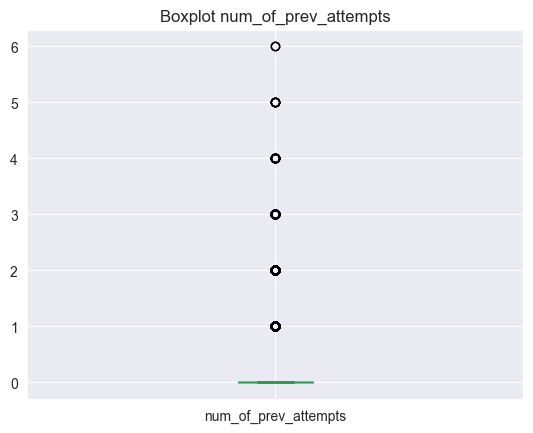

In [325]:
# Boxplot pentru numarul de incercari anterioare
current_feature = 'num_of_prev_attempts'
train_data.boxplot(column=current_feature)
plt.title(f"Boxplot {current_feature}")
plt.show()


Pentru `num_of_prev_attempts`, majoritatea valorilor sunt 0, iar valorile mai mari (outliers) apar mult mai rar. Acest lucru inseamna ca majoritatea studentilor nu au avut incercari anterioare de promovare a modulului

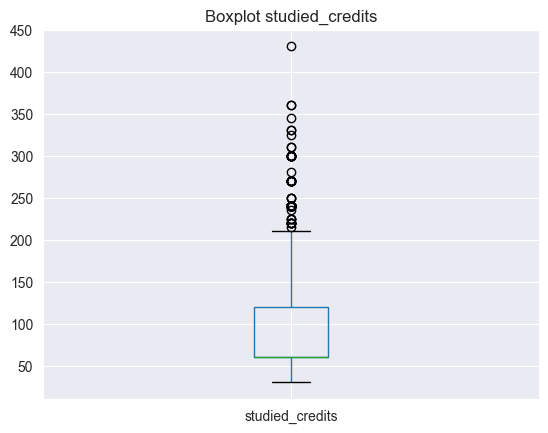

In [326]:
# Boxplot pentru numarul de credite studiate
current_feature = 'studied_credits'
train_data.boxplot(column=current_feature)
plt.title(f"Boxplot {current_feature}")
plt.show()


Pentru `studied_credits`, majoritatea valorilor sunt intre 60 si 120, iar mediana este 60. Totusi, apar si valori mult mai mari, pana la 430, care sunt marcate ca posibili oultiers. Acestea pot reprezenta studenti inscrisi la mai multe module sau cu un numar mai mare de credite studiate.

Valorile extreme pot influenta modelele sensibile la outlieri, deci trebuie sa le tratez in etapa de preprocesare

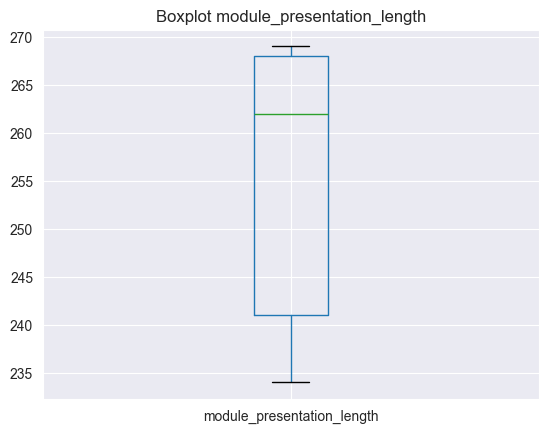

In [327]:
# Boxplot pentru lungimea modulului
current_feature = 'module_presentation_length'
train_data.boxplot(column=current_feature)
plt.title(f"Boxplot {current_feature}")
plt.show()

Pentru `module_presentation_length` valorile sunt intr-un interval mai restrans (aprox. intre 234 si 269), mediana fiind in partea superioara (~263). Nu apar outlieri evidenti, deci aceasta coloana pare mai stabila comparativ cu celelalte doua

##### -> n_assessments_early

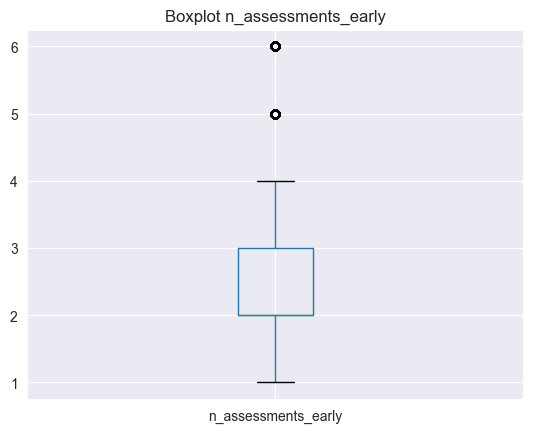

In [328]:
# Boxplot pentru lungimea modulului
current_feature = 'n_assessments_early'
train_data.boxplot(column=current_feature)
plt.title(f"Boxplot {current_feature}")
plt.show()

#### Atribute legate de scoruri

In acest grup analizez scorurile obtinute de studenti. `mean_score_early` si `weighted_mean_score_early` sunt atribute de intrare, iar `final_coursework_score` este variabila tinta pentru regresie


In [329]:
score_features = [
    "mean_score_early",
    "weighted_mean_score_early",
    "final_coursework_score"
]

# Statistici descriptive pentru scoruri
train_data[score_features].describe().transpose()

,count,mean,std,min,25%,50%,75%,max
mean_score_early,18770.0,74.364529,17.155703,0.0,66.500000,78.333333,86.666667,100.0
weighted_mean_score_early,18780.0,73.426873,16.570319,0.0,64.697674,76.000000,85.625000,100.0
final_coursework_score,18802.0,70.463286,16.846461,0.0,61.000000,73.124643,83.000000,100.0


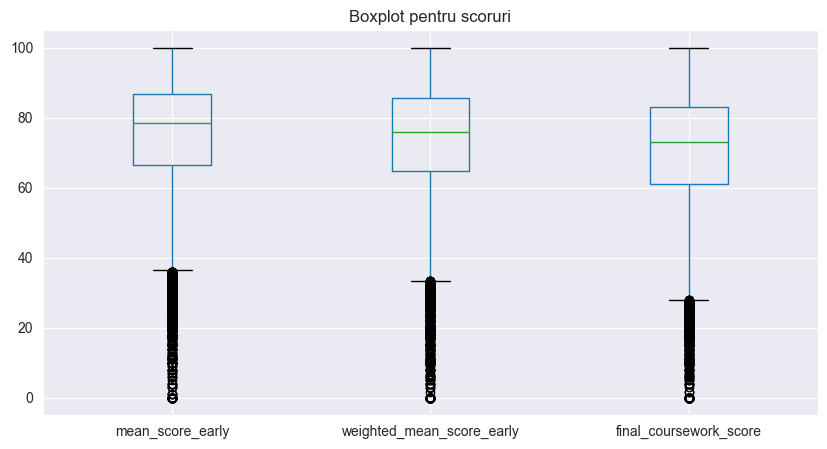

In [330]:
# Boxplot pentru scorurile studentilor
train_data[score_features].boxplot(figsize=(10, 5))
plt.title("Boxplot pentru scoruri")
plt.show()

Distributia scorurilor este asemanatoare pentru cele 3 atribute, ceea ce sugereaza ca scorurile obtinute la inceput pot avea legatura cu scorul final

- `mean_score_early` si `weighted_mean_score_early` au mediane apropiate, in jur de 76-78
- `final_coursework_score` are o mediana putin mai mica, aproximativ 73
- `weighted_mean_score_early` pare mai apropiat de `final_coursework_score` decat `mean_score_early`, deci este posibil sa fie un atribut important pentru regresie
- pentru toate cele 3 variabile apar multe valori mici marcate ca outlieri. Acestea pot reprezenta studenti cu performante scazute => pot fi importante pentru predictie, mai ales pentru cazurile de `Fail` sau `Withdrawn`

Acestea fiind spuse, intuiesc ca vom avea o corelatie intre scorurile initiale si cele finale. 

#### Atribute legate de inregistrare si retragere

In acest grup analizez `date_registration` si `date_unregistration`. Aceste coloane reprezinta momente relative fata de inceputul cursului, deci pot avea si valori negative

In [331]:
date_features = [
    "date_registration",
    "date_unregistration"
]

# Statistici descriptive pentru date_registration si date_unregistration
train_data[date_features].describe().transpose()

,count,mean,std,min,25%,50%,75%,max
date_registration,18799.0,-67.866163,47.851521,-311.0,-98.0,-54.0,-29.0,167.0
date_unregistration,3542.0,111.385940,62.186144,-196.0,59.0,108.0,159.0,444.0


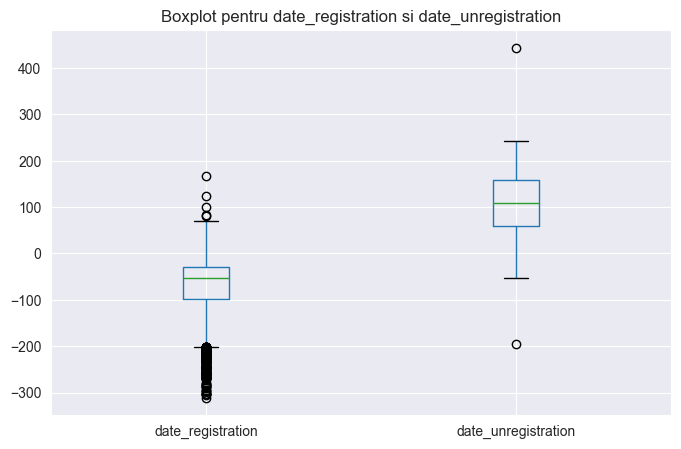

In [332]:
# Boxplot pentru date_registration si date_unregistration
train_data[date_features].boxplot(figsize=(8, 5))
plt.title("Boxplot pentru date_registration si date_unregistration")
plt.show()

Pentru `date_registration` majoritatea valorilor sunt negative, deci multi studenti s-au inscris inainte de inceperea cursului

Totusi, apar si valori pozitive, pana la 180, ceea ce inseamna ca exista studenti care s-au inscris dupa inceperea cursului. Apar si valori foarte mici, in jur de -300, marcate ca outlieri. Acestea pot reprezenta studenti care s-au inscris cu foarte mult timp inainte de inceperea cursului

Pentru `date_unregistration`, observ ca exista mult mai putine valori nenule=> multi studenti nu au renuntat la curs, deci nu au o data de retragere. Pentru studentii care au renuntat, mediana e pozitiva, aproximativ 100, deci retragerea apare de obicei dupa inceperea cursului


#### Atribute legate de activitatea pe platforma

In acest grup analizez cateva atribute care descriu activitatea studentilor pe platforma. Am ales `total_clicks_early` si cateva coloane `clicks_*`, deoarece acestea arata cat de mult au interactionat studentii cu diferite tipuri de resurse

In [333]:
click_features = [
    "total_clicks_early",
    "clicks_forumng",
    "clicks_oucontent",
    "clicks_quiz",
    "clicks_homepage",
    "clicks_subpage"
]

# Statistici descriptive pentru activitatea pe platforma
train_data[click_features].describe().transpose()

,count,mean,std,min,25%,50%,75%,max
total_clicks_early,18802.0,791.462557,860.590991,0.0,262.0,523.0,1004.75,12783.0
clicks_forumng,18742.0,194.106712,360.656511,0.0,24.0,89.0,222.00,6355.0
clicks_oucontent,18742.0,197.972735,291.112449,0.0,14.0,83.0,265.75,4914.0
clicks_quiz,18742.0,113.515580,203.611258,0.0,0.0,39.0,133.00,4535.0
clicks_homepage,18742.0,152.230925,179.562625,0.0,56.0,106.0,188.00,7075.0
clicks_subpage,18742.0,78.391100,97.690526,0.0,18.0,45.0,105.00,4150.0


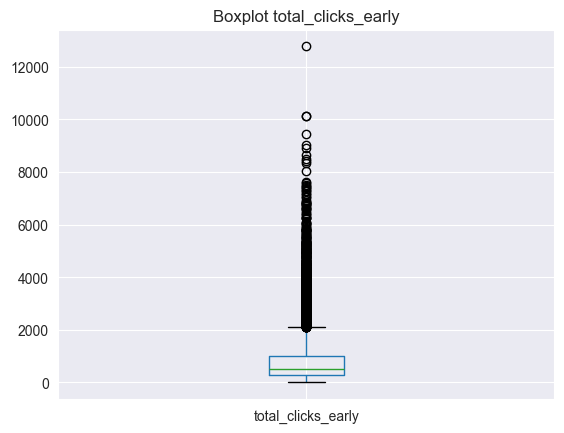

In [334]:
# Boxplot pentru numarul total de clickuri
current_feature = "total_clicks_early"

train_data.boxplot(column=current_feature)
plt.title(f"Boxplot {current_feature}")
plt.show()

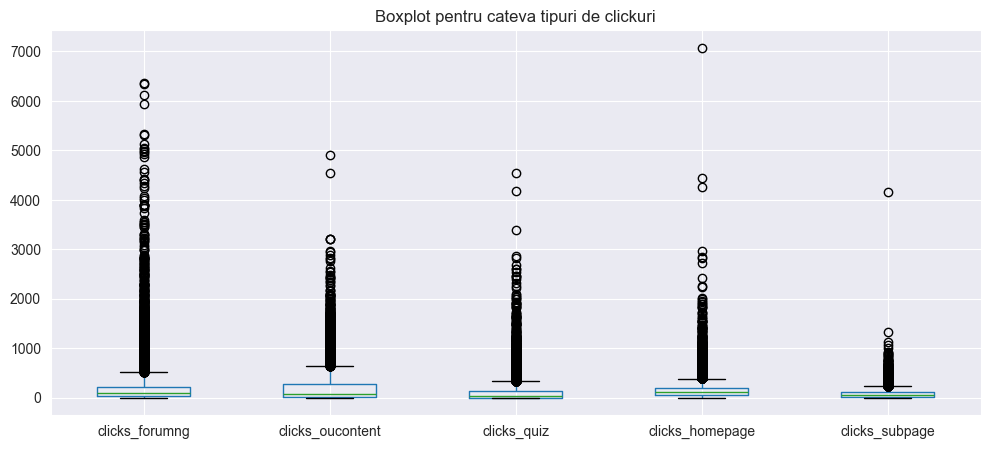

In [335]:
# Boxplot pentru cateva tipuri de clickuri
specific_click_features = [
    "clicks_forumng",
    "clicks_oucontent",
    "clicks_quiz",
    "clicks_homepage",
    "clicks_subpage"
]

train_data[specific_click_features].boxplot(figsize=(12, 5))
plt.title("Boxplot pentru cateva tipuri de clickuri")
plt.show()

Pentru atributele de activitate pe platforma, distributiile par foarte dezechilibrate. Majoritatea studentilor au un numar relativ mic de clickuri, dar exista si studenti cu valori foarte mari => multi posibili outliers

Pentru `total_clicks_early`, mediana este mult mai mica decat maximul, iar boxplotul arata multe valori marcate ca outlieri. Acest lucru sugereaza ca exista cativa studenti mult mai activi decat ceilalti

Aceeasi situatie apare si pentru coloanele `clicks_*`. Unele resurse au multe valori apropiate de 0, dar si valori foarte mari. Asta inseamna ca multi studenti folosesc putin sau deloc anumite resurse, in timp ce un numar mai mic de studenti le folosesc foarte mult

La preprocesare trebuie sa am grija la aceste atribute, deoarece apar multi outlieri si valorile au plaje foarte diferite. Totusi, nu vreau sa le elimin direct, pentru ca pot fi sugestive pentru nivelul de activitate al unui student pe platforma

#### Atribute numerice derivate

In acest grup analizez `refs_oucontent` si `macro_stats`. Aceste coloane au si valori negative, deci nu par sa reprezinte numaratori simple, ci atribute numerice derivate

In [336]:
derived_features = [
    "refs_oucontent",
    "macro_stats"]

# Statistici descriptive pentru atributele derivate
train_data[derived_features].describe().transpose()

,count,mean,std,min,25%,50%,75%,max
refs_oucontent,18742.0,193.933846,285.339918,-22.501328,14.527163,81.638701,259.922776,4816.530089
macro_stats,18802.0,0.004035,1.007548,-3.848168,-0.688035,0.000221,0.682404,3.942975


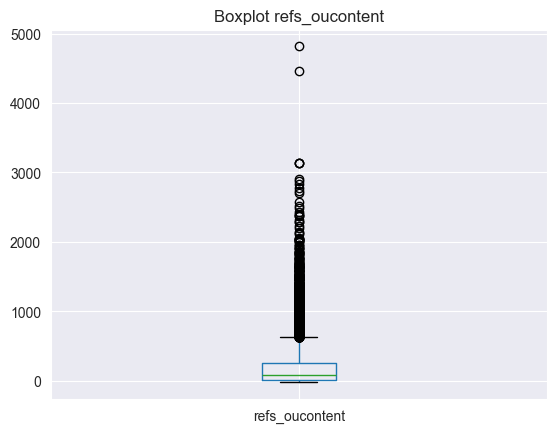

In [337]:
# Boxplot pentru refs_oucontent
current_feature = "refs_oucontent"

train_data.boxplot(column=current_feature)
plt.title(f"Boxplot {current_feature}")
plt.show()

`refs_oucontent` are distributia foarte asemanatoare cu `clicks_oucontent`, deci pare a fi derivat din el cumva

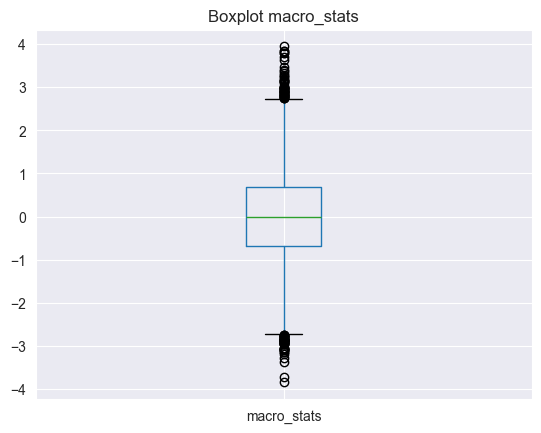

In [338]:
# Boxplot pentru macro_stats
current_feature = "macro_stats"

train_data.boxplot(column=current_feature)
plt.title(f"Boxplot {current_feature}")
plt.show()

Pentru `macro_stats`, valorile sunt centrate in jurul lui 0, iar deviatia standard este aproximativ 1. Acest lucru sugereaza ca atributul este standardizat si reprezinta un fel de scro agregat al studentului


### Atribute categoriale si ordinale

Pentru atributele categoriale si ordinale calculez:
- Numărul de exemple din setul de date care nu au valori lipsă
- Numărul de valori unice (cate categorii are fiecare atribut)


In [339]:
# Combin atributele categoriale si ordinale
cat_ord_features = categorical_features + ordinal_features

# Calculez numarul de valori nenule si numarul de valori unice
rows = []
for col in cat_ord_features:
    rows.append({
        'Atribut': col,
        'Nr. exemple fara valori lipsa': train_data[col].notna().sum(),
        'Nr. valori unice': train_data[col].nunique()
    })

pd.DataFrame(rows)

,Atribut,Nr. exemple fara valori lipsa,Nr. valori unice
0,code_module,18802,6
1,code_presentation,18802,4
2,gender,18802,2
3,region,18802,13
4,disability,18802,2
5,highest_education,18802,5
6,imd_band,18028,10
7,age_band,18802,3
8,clicks_freq_init,18742,3


In [340]:
# Afisez frecventa valorilor pentru fiecare atribut
for col in cat_ord_features:
    print(train_data[col].value_counts())
    print('\n')

code_module
FFF    5016
BBB    4679
DDD    3967
CCC    2722
EEE    1855
AAA     563
Name: count, dtype: int64


code_presentation
2014J    6506
2013J    5018
2014B    4239
2013B    3039
Name: count, dtype: int64


gender
M    10978
F     7824
Name: count, dtype: int64


region
Scotland                2189
East Anglian Region     1853
South Region            1825
London Region           1692
North Western Region    1566
South West Region       1416
West Midlands Region    1404
Wales                   1339
East Midlands Region    1284
South East Region       1217
Yorkshire Region        1102
North Region            1090
Ireland                  825
Name: count, dtype: int64


disability
N    17094
Y     1708
Name: count, dtype: int64


highest_education
A Level or Equivalent          8611
Lower Than A Level             6775
HE Qualification               3052
Post Graduate Qualification     217
No Formal quals                 147
Name: count, dtype: int64


imd_band
30-40%     2010
20-30

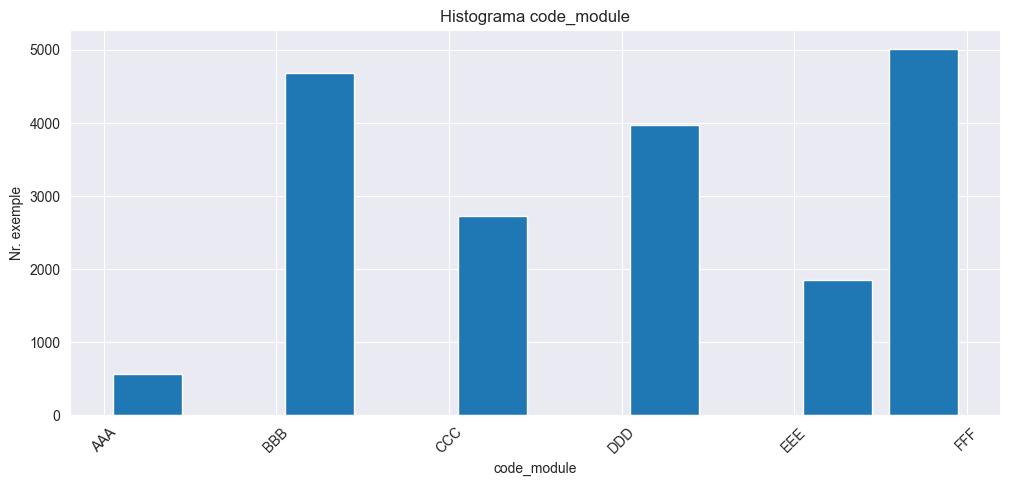

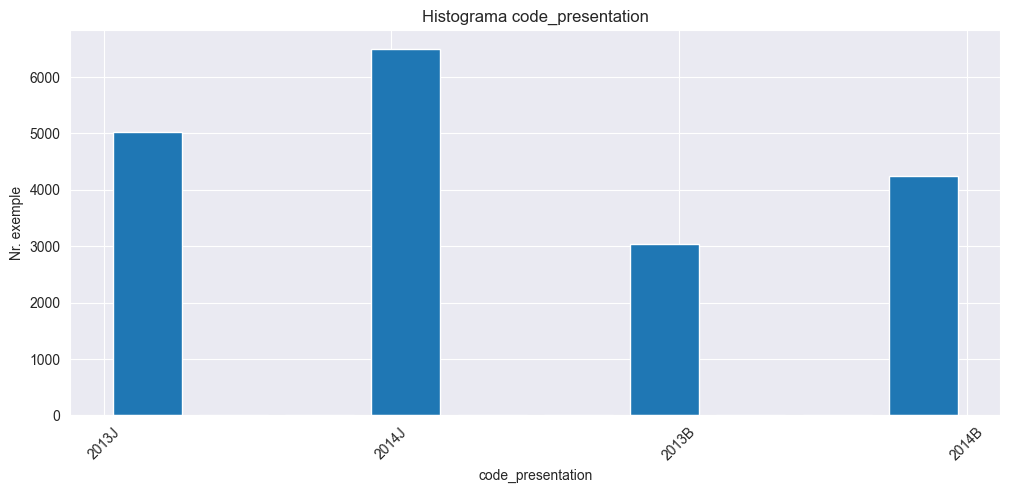

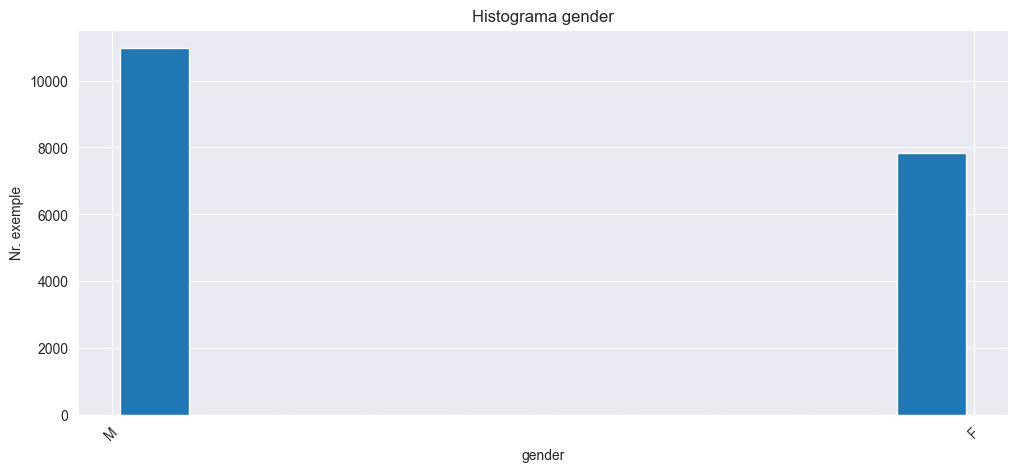

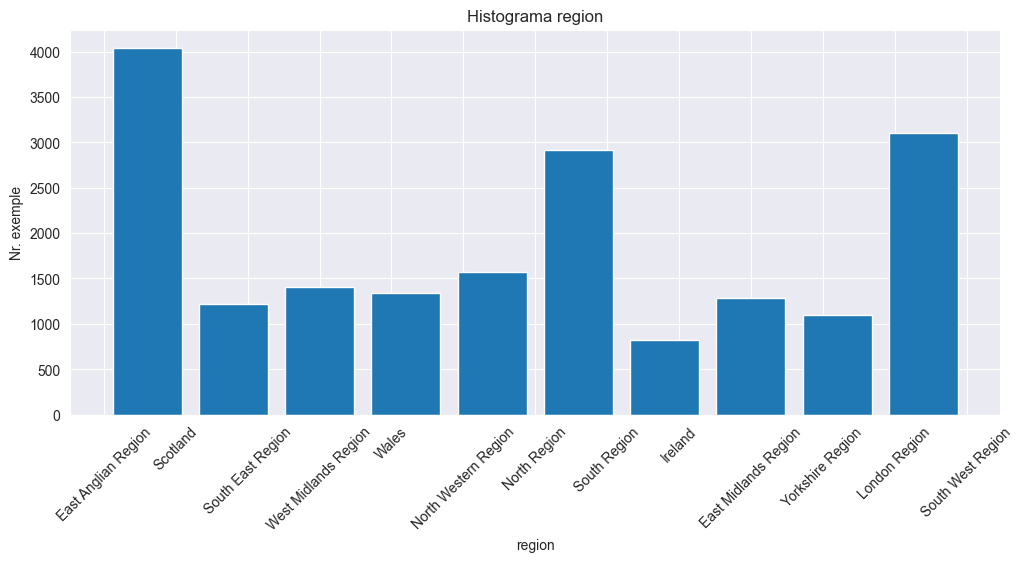

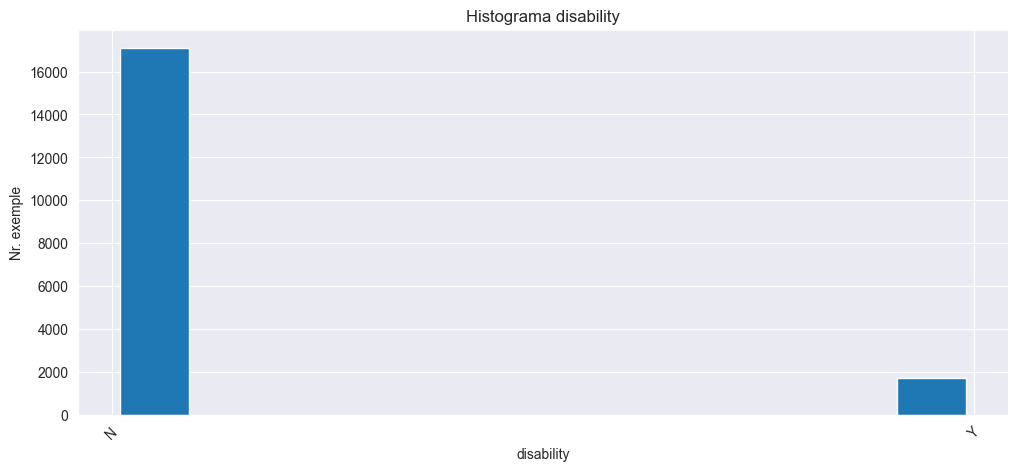

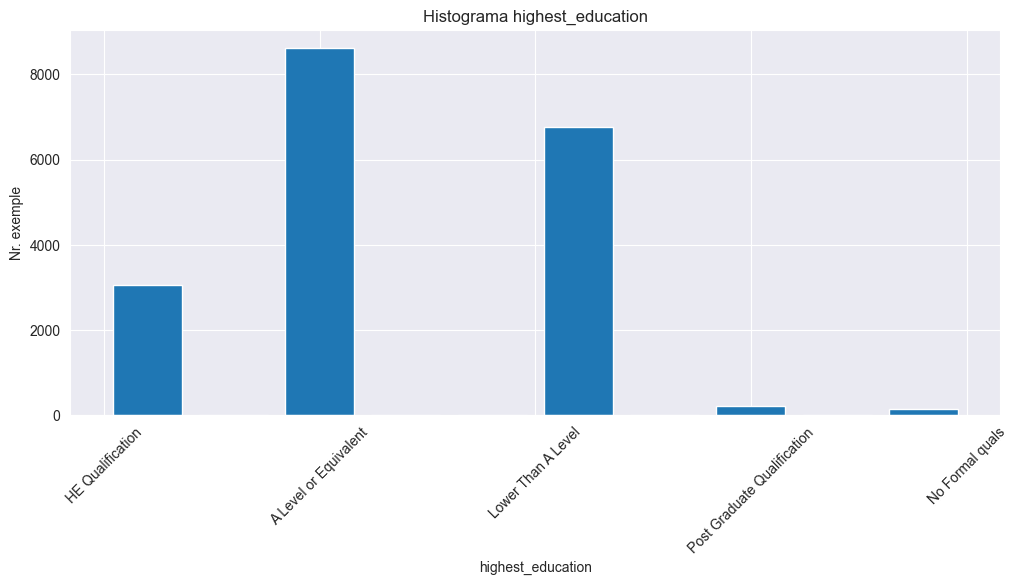

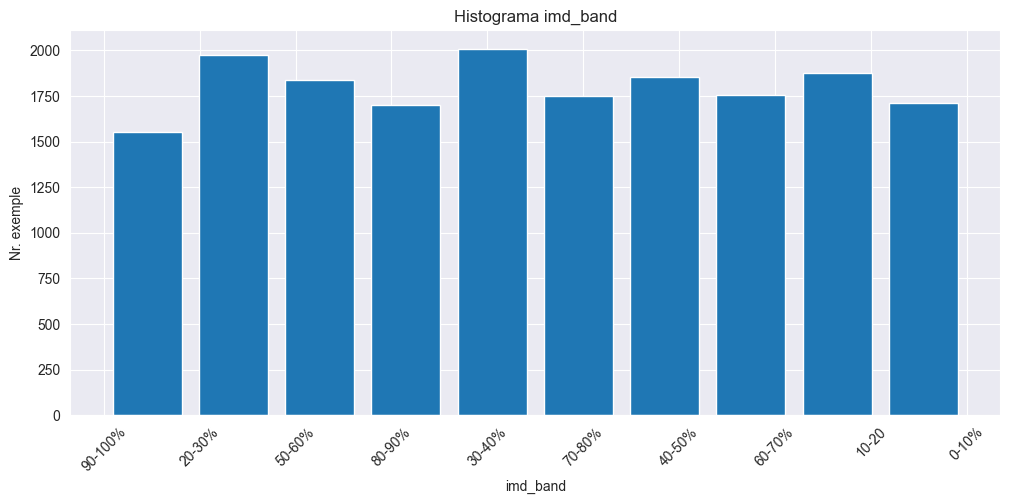

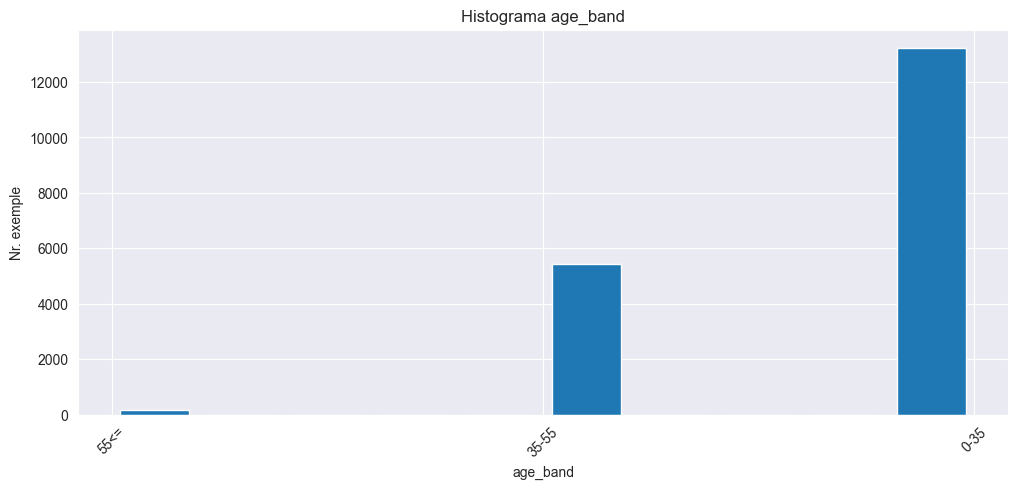

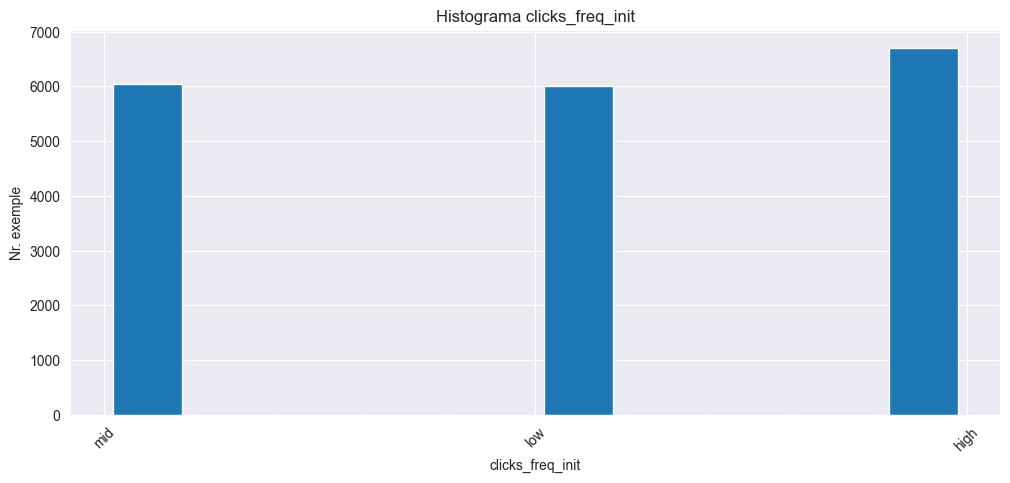

In [341]:
# Afisez distributia valorilor pentru fiecare atribut
for col in cat_ord_features:
    hist = train_data[col].hist(rwidth=0.8, figsize=(12, 5))

    plt.title(f"Histograma {col}")
    plt.xlabel(col)
    plt.ylabel("Nr. exemple")
    plt.xticks(rotation=45)
    plt.show()

Din statsistici si grafice reies urmatoarele observatii:

- `imd_band` si `clicks_freq_init` au cateva valori lipsa, in rest atributele categriale si ordinale sunt complete

- `gender` si `disability` au 2 valori unice, deci sunt atribute binare => pot fi encodate in valori numerice de tip 0/1.

- pentru `code_module`, `code_presentation`, `region` nu exista o ordine logica, deci o sa folosesc o encodare one-hot

- pentru `highest_education`, `imd_band`, `age_band` si `clicks_freq_init`  poate exista o ordine logica: 
    - `highest_education`:  `No Formal quals` < `Lower Than A Level` < `A Level or Equivalent` < `HE Qualification` < `Post Graduate Qualification`

    - `imd_band`:  `0-10%` < `10-20%` < `20-30%` < `30-40%` < `40-50%` < `50-60%` < `60-70%` < `70-80%` < `80-90%` < `90-100%`

    - `age_band`:  `0-35` < `35-55` < `55<=`

    - `clicks_freq_init`:  `low` < `mid` < `high`

=> ar trebui sa folosesc probabil ordinal encoding

Din histograme reiese ca atributele categoriale si ordinale au distributii diferite. Unele atribute sunt relativ echilibrate, cum este `imd_band` sau `clicks_freq_init`, iar altele sunt mai dezechilibrate, cum este `disability`, unde majoritatea studentilor nu dizabilitati

Cateva observatii mai importante:

- `code_module`: modulele nu au o distributie uniforma, cele mai multe exemple sunt pentru `FFF`, `BBB` si `DDD`, iar pentru `AAA` sunt semnificativ mai putine
- `gender`: e o diferenta destul de semnificativa intre numarul de studenti de gen `M` decat `F`, fiind mai multi studenti de gen masculin
- `disability`: distributia e foarte dezechilibrata, majoritatea valorilor fiind `N`
- `highest_education`: cele mai frecvente valori sunt `A Level or Equivalent` si `Lower Than A Level`, iar valorile `Post Graduate Qualification` si `No Formal quals` apar foarte rar
- `age_band`: majoritatea studentilor sunt in categoria `0-35`, iar categoria `55<=` apare foarte rar
- `clicks_freq_init`: valorile `low`, `mid` si `high` sunt destul de apropiate ca frecventa

Distibutiile vor influenta modelele, deoarece valorile rare pot fi invatate mai greu.
Pentru atribute precum `code_module`, `region`, `highest_education`, `disability` sau `age_band`, unele categorii apar mult mai rar decat altele. Din acest motiv, ma astept ca modelul sa invete mai bine tiparele pentru categoriile frecvente si sa generalizeze mai greu pentru categoriile cu putine exemple

### 2. Analiza echilibrului de clase


In aceasta parte analizez distributia claselor pentru target-ul pentru clasificare `final_result`

final_result
Pass           8990
Fail           4156
Withdrawn      3554
Distinction    2102
Name: count, dtype: int64


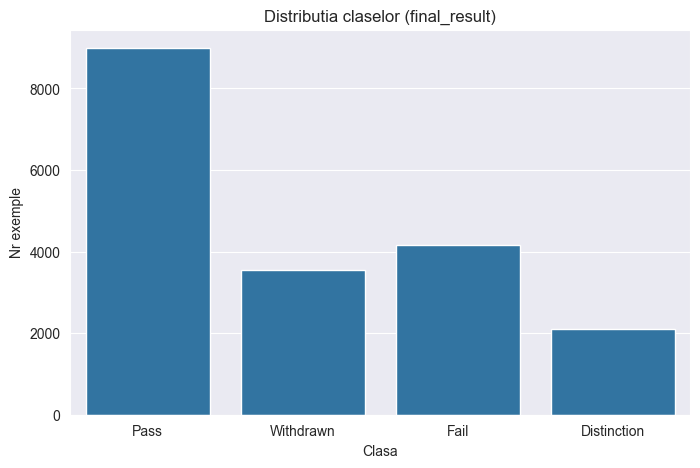

In [342]:
print(train_data['final_result'].value_counts())

# Target Variable Countplot
sns.set_style('darkgrid')
plt.figure(figsize = (8,5))
sns.countplot(x='final_result', data=train_data)

plt.title("Distributia claselor (final_result)")
plt.xlabel("Clasa")
plt.ylabel("Nr exemple")

plt.show()

In [343]:
# Afisez si procentele pentru fiecare clasa
class_percentages = train_data["final_result"].value_counts(normalize=True) * 100
class_percentages.round(2)


final_result
Pass           47.81
Fail           22.10
Withdrawn      18.90
Distinction    11.18
Name: proportion, dtype: float64

Din grafic si statistici reiese un dezechilibru destul de puternic al claselor. Clasa `Pass` apare mult mai des decat celelalte clase (apropae jumatate din toate exemplele), deci modelul poate fi tentat sa prezica mai des `Pass`, chiar si atunci cand exemplul apartine altei clase.

- `Fail` si `Withdrawn` au frecvente apropiate, dar sunt mult sub clasa `Pass`
- `Distinction` este clasa cu cele mai putine exemple
- din cauza acestui dezechilibru, accuracy nu este suficienta pentru evaluare

La evaluarea modelelor de clasificare trebuie sa folosesc si metrici precum precision, recall si F1-score, pentru a vedea cum se comporta modelul pe fiecare clasa in parte

### 3. Analiza corelației între atribute

#### Atribute numerice
In aceasta parte analizez corelatia dintre atributele numerice, pentru a vedea daca exista atribute care masoara informatii asemanatoare, care pot fi redundante

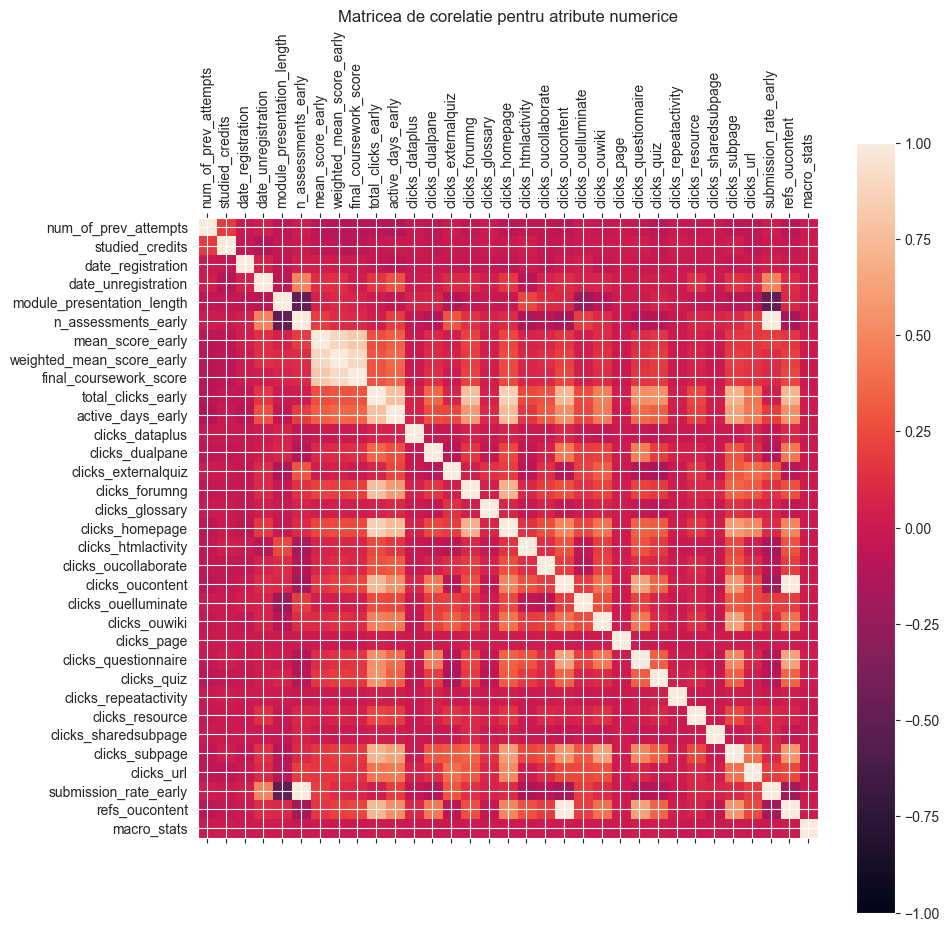

In [344]:
cols = numerical_features

# calculate correlation between all columns
correlations = train_data[cols].corr()

# create a new figure
fig = plt.figure(figsize=(10, 10))

# 111: 1x1 frid, first subplot
ax = fig.add_subplot(111)

# normalize dtata using vmin, vmax
cax = ax.matshow(correlations, vmin=-1, vmax=1)

# add a colorbar to the plot
fig.colorbar(cax)

# define ticks
ticks = np.arange(0, len(cols), 1)

# set x and y tick marks
ax.set_xticks(ticks)
ax.set_yticks(ticks)

# set x and y tick labels
ax.set_xticklabels(cols, rotation=90)
ax.set_yticklabels(cols)

# draw the correlation matrix
plt.title("Matricea de corelatie pentru atribute numerice")
plt.show()

Din matricea de corelatie reies cateva relatii importante intre atributele numerice:

Corelatii foarte mari (alb):
- `submission_rate_early` <-> `n_assessments_early`
- `refs_oucontent` <-> `clicks_oucontent`

Aceste perechi de variabile par sa contina informatii foarte apropiate, deci pot fi partial redundante. In etapa de preprocesare/modelare pot testa daca merita sa pastrez ambele atribute sau daca pot elimina unul dintre ele pentru a simplifica modelul

Corelatii mari (galben deschis):
- `mean_score_early` <-> `weighted_mean_score_early`

Acest lucru este normal, deoarece ambele variabile descriu performanta studentului la inceputul cursului. Ma astept ca aceste scoruri sa fie importante pentru predictia scorului final. Asa cum am anticipat la punctul 1 (graficul _"Boxplot pentru scoruri"_), scorurile sunt puternic corelate intre ele

- `total_clicks_early` <-> `active_days_early`

Studentii care au mai multe zile active tind sa aiba si mai multe clickuri pe platforma. Asta are sens, deoarece ambele atribute descriu nivelul de interactiune cu platforma.


- coloanele `clicks_*` intre ele si cu `total_clicks_early`/ `refs_oucontent`  
Aceste atribute descriu diferite tipuri de interactiune cu platforma, deci este normal sa fie corelate intre ele.

Corelatii negative (mov inchis):
- `module_presentation_length` <-> `n_assessments_early`, `submission_rate_early`
- `clicks_oucontent`, `refs_oucontent` <-> `n_assessments_early`, `submission_rate_early`

Aceste corelatii negative arata ca atunci cand un atribut creste, celalalt tinde sa scada. De exemplu, modulele mai lungi tind sa aiba mai putine evaluari/submisii devreme

Concluzia principala este ca unele atribute numerice sunt corelate puternic intre ele. La preprocesare nu le voi elimina automat, dar voi tine cont de posibila redundanta

#### Matricea de corelatie partiala

Matricea completa de corelatie contine multe atribute numerice si este mai greu de interpretat vizual. De aceea, am ales un subset de atribute mai importante, pe care le-am analizat si anterior

In aceasta matrice am inclus si `final_coursework_score`, deoarece vreau sa vad ce atribute numerice sunt corelate cu tinta de regresie

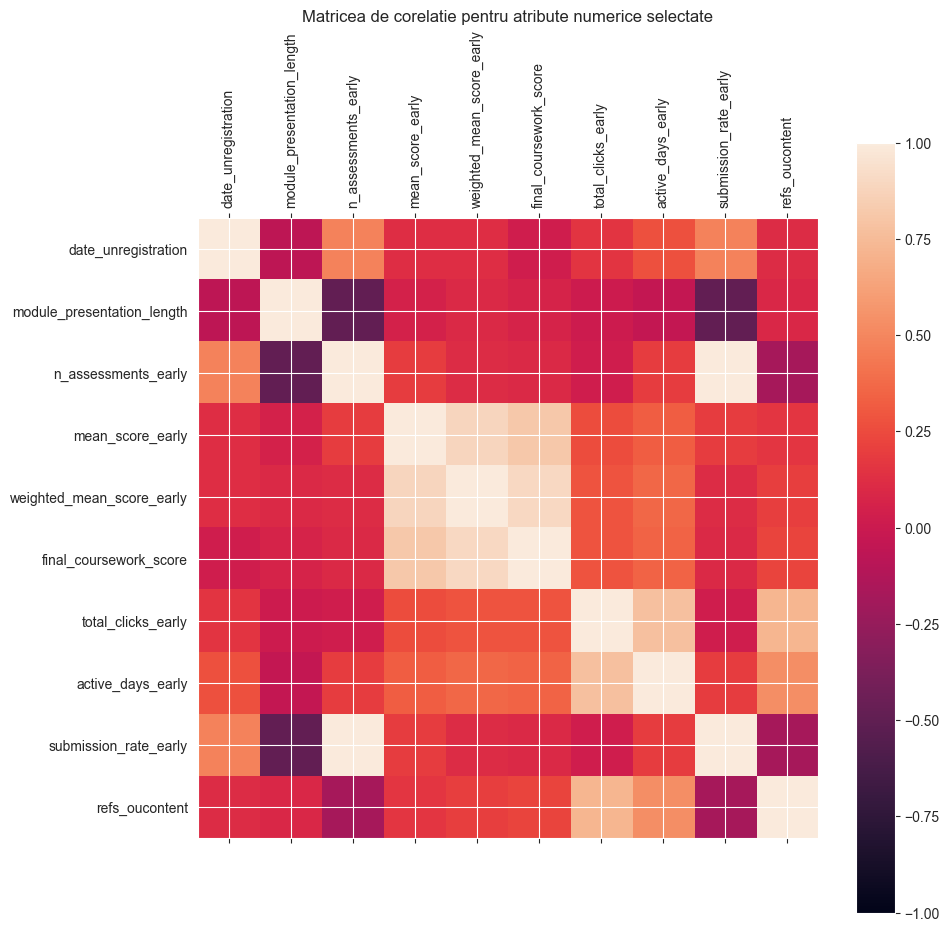

In [345]:
cols = [
    'date_unregistration',
    'module_presentation_length',
    'n_assessments_early',
    'mean_score_early',
    'weighted_mean_score_early',
    'final_coursework_score',
    'total_clicks_early',
    'active_days_early',
    'submission_rate_early',
    'refs_oucontent'
    ]

# calculate correlation between all columns
correlations = train_data[cols].corr()

# create a new figure
fig = plt.figure(figsize=(10, 10))

# 111: 1x1 frid, first subplot
ax = fig.add_subplot(111)

# normalize dtata using vmin, vmax
cax = ax.matshow(correlations, vmin=-1, vmax=1)

# add a colorbar to the plot
fig.colorbar(cax)

# define ticks
ticks = np.arange(0, len(cols), 1)

# set x and y tick marks
ax.set_xticks(ticks)
ax.set_yticks(ticks)

# set x and y tick labels
ax.set_xticklabels(cols, rotation=90)
ax.set_yticklabels(cols)

# draw the correlation matrix
plt.title("Matricea de corelatie pentru atribute numerice selectate")
plt.show()

Din matricea de corelatie pentru atributele selectate se observa mai clar legaturile dintre atribute si mai ales ca `mean_score_early`, `weighted_mean_score_early` si `final_coursework_score` sunt puternic corelate intre ele. Acest lucru confirma observatia facuta anterior la boxplotul pentru scoruri-> scorurile obtinute la inceputul cursului pot fi relevante pentru predictia scorului final

### Analiza relatiei dintre atribute si variabilele tinta

In aceasta etapa, analizez relatia dintre atribute si cele doua task-uri:
- clasificare: predictia variabilei `final_result`
- regresie: predictia variabilei `final_coursework_score`

Mai exact, voi analiza:
- un atribut numeric in raport cu sarcina de clasificare
- un atribut categorial in raport cu sarcina de clasificare
- un atribut numeric in raport cu sarcina de regresie
- un atribut categorial in raport cu sarcina de regresie

#### Numeric + Clasificare

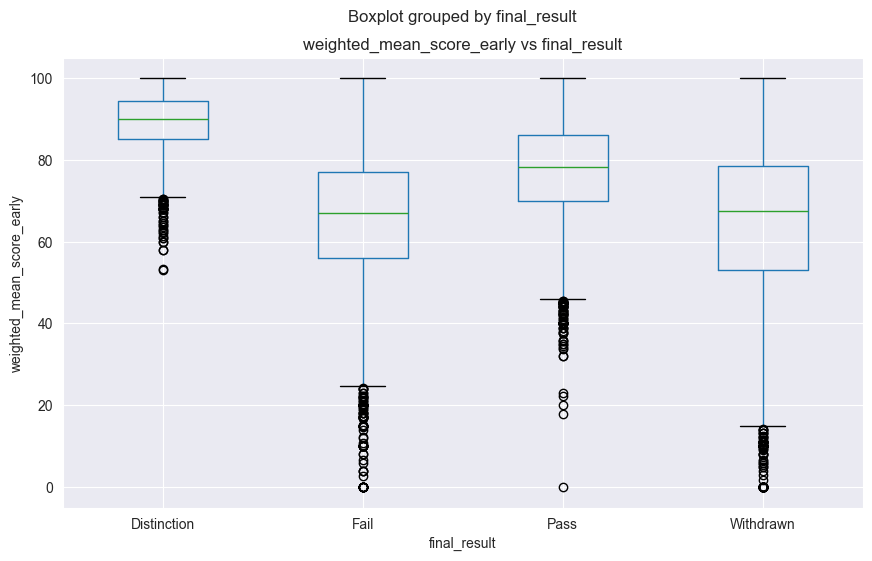

,count,mean,std,min,25%,50%,75%,max
final_result,,,,,,,,
Distinction,2102.0,88.882707,7.354160,53.1875,85.0,90.000000,94.363636,100.0
Fail,4146.0,65.306643,16.535605,0.0000,56.0,67.000000,77.000000,100.0
Pass,8984.0,77.267420,11.505093,0.0000,70.0,78.333333,86.000000,100.0
Withdrawn,3548.0,64.034210,20.558741,0.0000,53.0,67.500000,78.569444,100.0


In [346]:
feature = 'weighted_mean_score_early'
target = 'final_result'

train_data.boxplot(column=feature, by=target, figsize=(10, 6))
plt.title(f"{feature} vs {target}")
plt.xlabel(target)
plt.ylabel(feature)
plt.show()

train_data.groupby(target)[feature].describe()


Studentii care au avut performante finale bune (au label-ul `Distinction` sau `Pass`) au avut scoruri early bune (mari), iar cei cu performante finale slabe (`Fail` sau `Withdrawn`) au scoruri early slabe (mici). Deci, asa cum am anticipat, avem o corelatie mare intre aceste doua atribute.

#### Categorial + Clasificare

In [347]:
feature = 'highest_education'
target = 'final_result'

CrosstabResult = pd.crosstab(index=train_data[feature], columns=train_data[target])
print(CrosstabResult)

ChiSqResult = chi2_contingency(CrosstabResult)
# print(ChiSqResult)

# P-Value is the Probability of H0 being True
# If P-Value > 0.05 then only we Accept the assumption(H0)
# P-Value >= 0.05 => variabile necorelate
# P-Value < 0.05 => variabile corelate
print(f'P-Value of the ChiSq Test for {feature}:', ChiSqResult[1])


final_result                 Distinction  Fail  Pass  Withdrawn
highest_education                                              
A Level or Equivalent               1072  1698  4373       1468
HE Qualification                     539   493  1522        498
Lower Than A Level                   416  1900  2944       1515
No Formal quals                       10    39    60         38
Post Graduate Qualification           65    26    91         35
P-Value of the ChiSq Test for highest_education: 1.3193213173918145e-134


P-Value = 1.3193e-134 => P-Value << 0.05 => variabilele `highest_education` si `final_result` sunt puternic corelate. Cu alte cuvinte, nivelul de educatie este in stransa legatura cu rezultatul final al studentilor

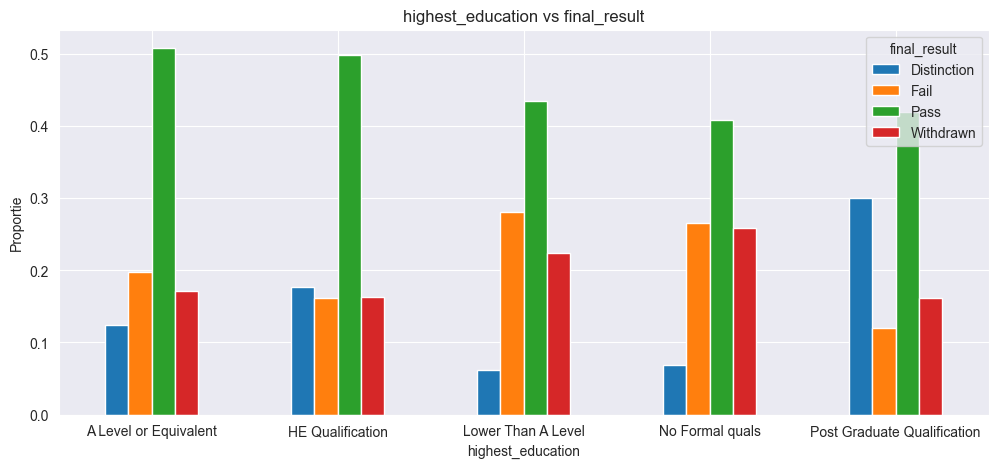

In [348]:
# Grafic cu proportiile claselor pt fiecare nivel de educatie
crosstab_percent = pd.crosstab(
    index=train_data[feature],
    columns=train_data[target],
    normalize="index")

crosstab_percent.plot(kind="bar", figsize=(12, 5))

plt.title(f"{feature} vs {target}")
plt.xlabel(feature)
plt.ylabel("Proportie")
plt.xticks(rotation=0)
plt.legend(title=target)
plt.show()

Din grafic reiese ca proportiile claselor difera in functie de nivelul de educatie:

- pentru toate nivelurile de educatie, clasa `Pass` ramane cea mai frecventa, dar proportiile nu sunt identice
- pentru `Post Graduate Qualification` si `HE Qualification`, proportia de `Distinction` este mai mare decat pentru celelalte categorii
- pentru `Lower Than A Level` si `No Formal quals`, proportiile de `Fail` si `Withdrawn` sunt mai mari

In concluzie, `highest_education` este un atribut foarte util pentru etapa de clasificare. La preprocesare il voi trata ca atribut ordinal, deoarece nivelurile de educatie au o ordine logica (am mentionat-o mai sus)

In [349]:
# gender vs final_result

feature = 'gender'
target = 'final_result'

CrosstabResult = pd.crosstab(index=train_data[feature], columns=train_data[target])
print(train_data[feature].value_counts())
print('\n')
print(CrosstabResult)

ChiSqResult = chi2_contingency(CrosstabResult)
# print(ChiSqResult)

# P-Value is the Probability of H0 being True
# If P-Value > 0.05 then only we Accept the assumption(H0)
# P-Value >= 0.05 => variabile necorelate
# P-Value < 0.05 => variabile corelate
print(f'P-Value of the ChiSq Test for {feature}:', ChiSqResult[1])

gender
M    10978
F     7824
Name: count, dtype: int64


final_result  Distinction  Fail  Pass  Withdrawn
gender                                          
F                     866  1649  3883       1426
M                    1236  2507  5107       2128
P-Value of the ChiSq Test for gender: 0.00026949878365848843


P-Value = 0.00026 < 0.05 => gender si final_result sunt corelate statistic. Totusi, marimea efectului este mica, iar din grafic se vede ca distributiile pe clase sunt aproape identice intre M si F, deci gender nu pare un predictor puternic in sine

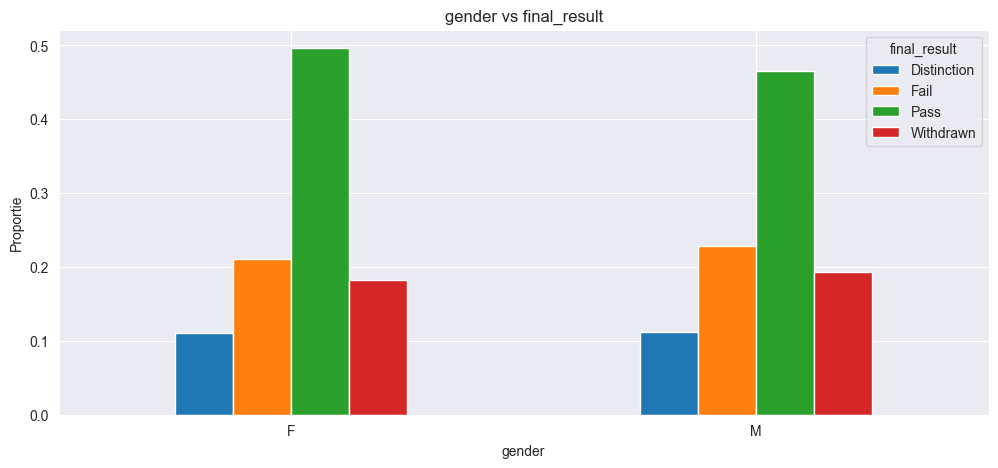

In [350]:
# Grafic cu proportiile claselor pt fiecare nivel de educatie
crosstab_percent = pd.crosstab(
    index=train_data[feature],
    columns=train_data[target],
    normalize="index"
)

crosstab_percent.plot(kind="bar", figsize=(12, 5))

plt.title(f"{feature} vs {target}")
plt.xlabel(feature)
plt.ylabel("Proportie")
plt.xticks(rotation=0)
plt.legend(title=target)
plt.show()

Diferenta dintre distributiile pe clase nu este foarte mare vizual. Am facut aceasta verificare mai mult din curiozitate personala :)

#### Numeric + Regresie

Pentru aceasta analiza folosesc atributul numeric `weighted_mean_score_early` si tinta de regresie `final_coursework_score`. Vreau sa vad (sau mai bine zis sa confirm) daca scorul ponderat obtinut la inceputul cursului are legatura cu scorul final obtinut la coursework

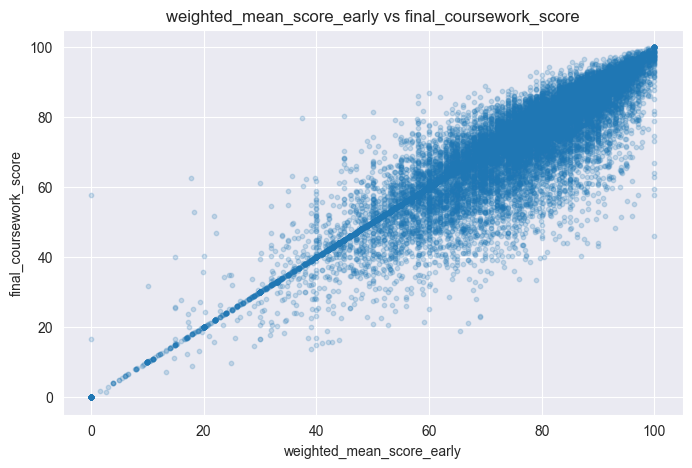

Corelatia pearson: 0.8988588573563996


In [351]:
feature = 'weighted_mean_score_early'
target = 'final_coursework_score'

plt.figure(figsize=(8, 5))
plt.scatter(x=train_data[feature], y=train_data[target], s=10, alpha=0.2)
plt.title(f"{feature} vs {target}")
plt.xlabel(feature)
plt.ylabel(target)
plt.show()

# corelatia pearson
correlation = train_data[feature].corr(train_data[target])
print(f'Corelatia pearson: {correlation}')


Din grafic se observa o relatie pozitiva clara intre `weighted_mean_score_early` si `final_coursework_score`. Cu cat scorul ponderat de la inceput este mai mare, cu atat scorul final tinde sa fie mai mare

Corelatia Pearson este aprox. 0.90, ceea ce indica o corelatie pozitiva puternica, fapt ce confirma observatiile anterioare (scorurile obtinute la inceputul cursului sunt foarte relevante pentru predictia scorului final)

In etapa de regresie ma astept ca `weighted_mean_score_early` sa fie unul dintre cele mai importante atribute pentru model

Am analizat si `total_clicks_early`, deoarece vreau sa vad daca activitatea studentului pe platforma are legatura cu scorul final

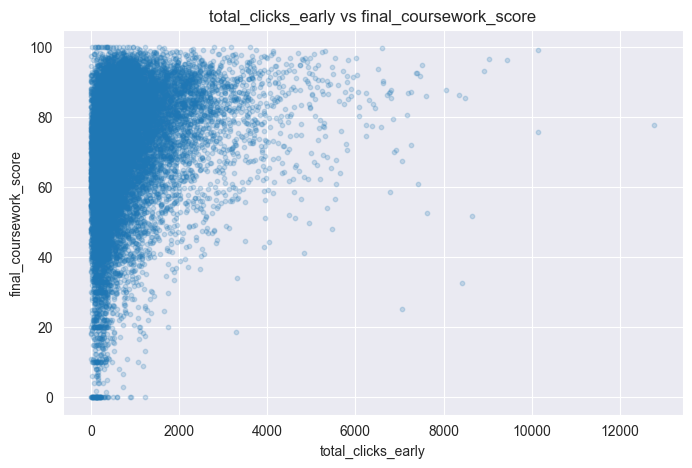

Corelatia pearson: 0.28739536122572


In [352]:
feature = 'total_clicks_early'
target = 'final_coursework_score'

plt.figure(figsize=(8, 5))
plt.scatter(x=train_data[feature], y=train_data[target], s=10, alpha=0.2)
plt.title(f"{feature} vs {target}")
plt.xlabel(feature)
plt.ylabel(target)
plt.show()

# corelatia pearson
correlation = train_data[feature].corr(train_data[target])
print(f'Corelatia pearson: {correlation}')

Pentru `total_clicks_early`, corelatia Pearson cu `final_coursework_score` este aprox. 0.29, deci exista o corelatie pozitiva, dar destul de slaba.

Din grafic se observa ca studentii cu foarte putine clickuri pot avea scoruri finale foarte diferite, de la 0 pana la 100. In acelasi timp, pentru valori mari ale numarului de clickuri, scorurile tind sa fie in general mai ridicate, dar relatia nu este la fel de clara ca in cazul variabilei weighted_mean_score_early

Acest lucru sugereaza ca activitatea pe platforma poate ajuta la predictia scorului final, dar nu e nici pe departe suficienta singura. Pentru regresie, ma astept ca `total_clicks_early` sa fie mult mai putin util decat `weighted_mean_score_early`

#### Categorial + Regresie

##### -> region vs final_coursework_score

Pentru aceasta analiza folosesc atributul categorial `region` si tinta de regresie `final_coursework_score`. Pentru ca deja stiu importanta atributului `highest_education`, vreau sa verific daca scorul final obtinut difera in functie de regiunea studentului

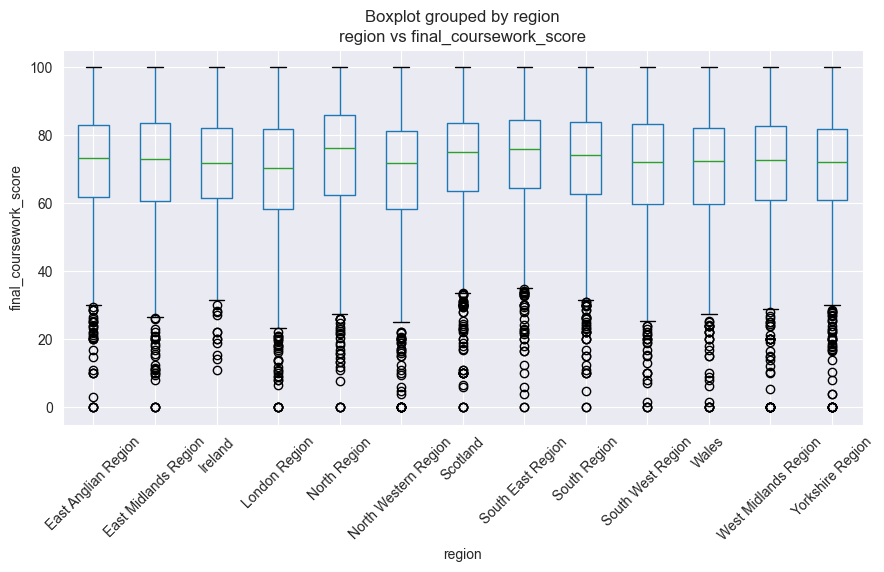

,count,mean,std,min,25%,50%,75%,max
region,,,,,,,,
East Anglian Region,1853.0,70.816447,15.918602,0.000000,61.675000,73.214286,82.909091,100.0
East Midlands Region,1284.0,70.321114,17.057430,0.000000,60.577500,72.836765,83.333333,100.0
Ireland,825.0,70.479065,15.091397,10.948718,61.450000,71.700000,82.000000,100.0
London Region,1692.0,68.493027,17.508230,0.000000,58.159167,70.165263,81.547980,100.0
North Region,1090.0,72.247791,17.906471,0.000000,62.310417,76.192500,85.845395,100.0
North Western Region,1566.0,68.487811,17.657232,0.000000,58.355000,71.759615,81.009868,100.0
Scotland,2189.0,72.161290,15.908483,0.000000,63.500000,75.043478,83.500000,100.0
South East Region,1217.0,72.413935,16.130652,0.000000,64.500000,75.851064,84.240000,100.0
South Region,1825.0,71.643150,16.110605,0.000000,62.736434,74.100000,83.687500,100.0


In [353]:
feature = 'region'
target = 'final_coursework_score'

train_data.boxplot(column=target, by=feature, figsize=(10, 5))
plt.title(f"{feature} vs {target}")
plt.xlabel(feature)
plt.xticks(rotation=45)
plt.ylabel(target)
plt.show()

train_data.groupby(feature)[target].describe()

Distributiile sunt foarte asemanatoare, deci `region` nu pare sa fie un atribut foarte puternic pentru regresie, cel putin analizat individual. Poate in combinatie cu alte atribute devine mai sugestiv

##### -> imd_band vs final_coursework_score


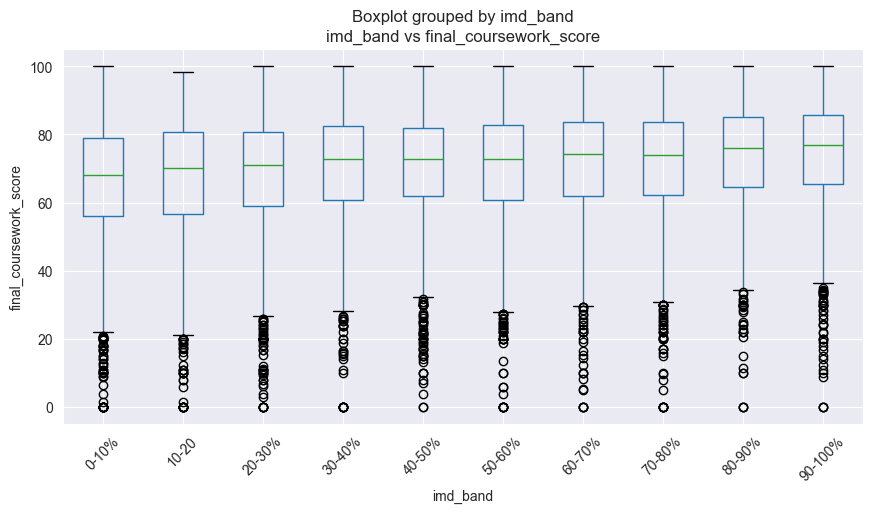

,count,mean,std,min,25%,50%,75%,max
imd_band,,,,,,,,
0-10%,1711.0,65.790920,18.186181,0.0,56.000000,68.100000,79.058025,100.00
10-20,1877.0,67.438302,17.614871,0.0,56.777778,70.290000,80.750000,98.44
20-30%,1976.0,68.483906,17.317952,0.0,59.000000,71.000000,80.762500,100.00
30-40%,2010.0,70.399721,16.261421,0.0,60.735938,72.685606,82.500000,100.00
40-50%,1853.0,70.409756,16.341689,0.0,62.000000,72.900000,82.000000,100.00
50-60%,1839.0,70.247141,16.844395,0.0,60.778602,72.870000,82.685000,100.00
60-70%,1758.0,71.619239,16.199964,0.0,62.025000,74.216111,83.664063,100.00
70-80%,1750.0,71.327759,16.478439,0.0,62.386250,74.000000,83.706667,100.00
80-90%,1700.0,73.456129,15.286340,0.0,64.695122,76.000000,85.000000,100.00


In [354]:
feature = 'imd_band'
target = 'final_coursework_score'

train_data.boxplot(column=target, by=feature, figsize=(10, 5))
plt.title(f"{feature} vs {target}")
plt.xlabel(feature)
plt.xticks(rotation=45)
plt.ylabel(target)
plt.show()

train_data.groupby(feature)[target].describe()

Pentru `imd_band` e o usoara crestere a scorului final pe masura ce intervalul creste. Studentii din benzile mai mari tind sa aiba mediane putin mai ridicate pentru `final_coursework_score`. Totusi, diferentele nu sunt foarte mari, iar distributiile se suprapun destul de mult

##### -> age_band vs final_coursework_score

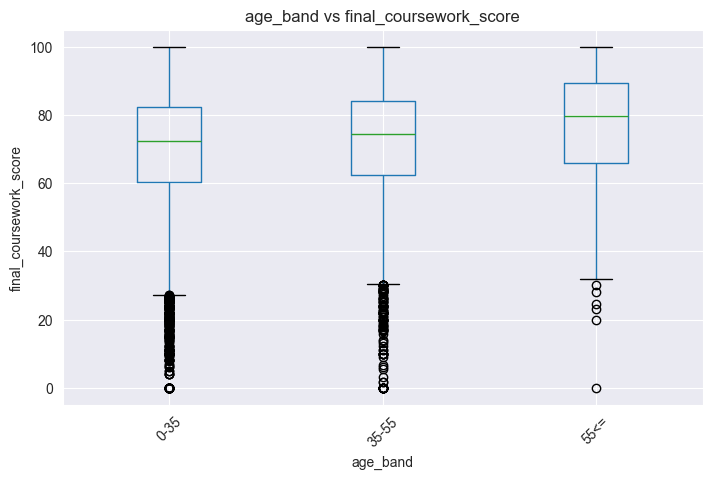

,count,mean,std,min,25%,50%,75%,max
age_band,,,,,,,,
0-35,13219.0,69.815730,16.921529,0.0,60.255865,72.410000,82.333333,100.0
35-55,5429.0,71.898464,16.504416,0.0,62.500000,74.567901,84.000000,100.0
55<=,154.0,75.453218,18.407726,0.0,65.943750,79.725000,89.325000,100.0


In [355]:
feature = "age_band"
target = "final_coursework_score"

train_data.boxplot(column=target, by=feature, figsize=(8, 5))
plt.title(f"{feature} vs {target}")
plt.suptitle("")
plt.xlabel(feature)
plt.xticks(rotation=45)
plt.ylabel(target)
plt.show()

train_data.groupby(feature)[target].describe()

Pentru `age_band`, studentii mai in varsta au mediane (=> scoruri) putin mai ridicate. Totusi, categoria `55<=` are mult mai putine exemple, deci si acesta e un factor care influenteaza distibutia


## 3.2. Preprocesarea datelor

### 1. Date lipsă pentru un atribut într-un eșantion


In [356]:
# Verific valorile lipsa din train si test intr-un tabel mai usor de urmarit
missing_values = pd.DataFrame({
                "missing_train": train_data.isna().sum(),
                "percent_train": (train_data.isna().sum()/len(train_data) * 100).round(2),
                "missing_test": test_data.isna().sum(),
                "percent_test": (test_data.isna().sum()/len(test_data) * 100).round(2) })

# Afisez doar coloanele care au cel putin o valoare lipsa in train sau test
has_missing_values = (missing_values["missing_train"] > 0) | (missing_values["missing_test"] > 0)
missing_values = missing_values[has_missing_values]

missing_values

,missing_train,percent_train,missing_test,percent_test
imd_band,774,4.12,215,4.57
date_registration,3,0.02,1,0.02
date_unregistration,15260,81.16,3815,81.17
n_assessments_early,15,0.08,4,0.09
mean_score_early,32,0.17,8,0.17
weighted_mean_score_early,22,0.12,6,0.13
clicks_dataplus,60,0.32,17,0.36
clicks_dualpane,60,0.32,17,0.36
clicks_externalquiz,60,0.32,17,0.36
clicks_forumng,60,0.32,17,0.36


Din tabel reies multe valori lipsa pentru:
- `date_unregistration `(peste 80%)
- `clicks_resource` (aprox 30%)
- `clicks_url` (aprox 30%)

Pentru `imd_band` sunt aprox. 4% valori lipsa

Pentru restul `clicks_*` sunt aprox. 0.30%

Pentru celelalte atribute numarul de valori lipsa este relativ mic (<0.20%)

O sa incerc mai multe metode de imputare, dar cea initiala ar fi urmatoarea, in functie de tipul atributelor, distibutia obtinuta la EDA si nr. de valori lipsa:

- pentru atributele numerice cu putine valori lipsa folosesc imputarea cu mediana
    - `date_registration`, `n_assessments_early`, `mean_score_early`, `weighted_mean_score_early`, `submission_rate_early`
    - aleg mediana deoarece aceste atribute pot avea valori extreme, iar mediana este mai robusta decat media

- pentru atributele categoriale/ordinale folosesc imputarea cu cea mai frecventa valoare
    - `imd_band`, `clicks_freq_init`
    - folosesc aceasta metoda deoarece atributele sunt categorice/ordinale, iar o medie nu ar avea sens pentru ele

- pentru coloanele de tip `clicks_*` si `refs_oucontent` folosesc imputarea cu 0
    - aceste coloane reprezinta interactiuni cu platforma, deci valoarea 0 poate fi interpretata ca lipsa accesarii acelei resurse
    - pentru `clicks_resource` si `clicks_url`, chiar daca procentul de valori lipsa este mai mare, pastrez aceeasi strategie pentru simplitate

- pentru `date_unregistration`:
    - asa cum am zis mai sus, coloana are foarte multe valori lipsa care cel mai probabil indica faptul ca studentul nu s a retras de la curs
    - deci, as putea sa creez un atribut nou `unregistered`, care indica daca studentul s a returas sau nu de la curs, bazat pe date_uregistration (1 daca studentul are data de retragere si 0 daca nu are)
  

Pentru imputare folosesc `SimpleImputer` din scikit-learn, deoarece este metoda recomandata in indicatii pentru imputare univariata

In [357]:
# copii ale seturilor initiale pentru etapa de imputare
train_imputed = train_data.copy()
test_imputed = test_data.copy()

### Imputarea atributelor numerice cu mediana

Pentru atributele numerice care au putine valori lipsa folosesc mediana. Am ales mediana deoarece este mai robusta la outliers decat media

In [358]:
# Atribute numerice pentru care folosesc imputarea cu mediana
median_impute_features = [
    "date_registration",
    "n_assessments_early",
    "mean_score_early",
    "weighted_mean_score_early",
    "submission_rate_early"
]

# Creez un SimpleImputer cu  median
median_imputer = SimpleImputer(strategy="median")

# Aplic fit pe train si transform pe train/test
train_imputed[median_impute_features] = median_imputer.fit_transform(train_imputed[median_impute_features])

test_imputed[median_impute_features] = median_imputer.transform(test_imputed[median_impute_features])

In [359]:
print("train:")
print(train_imputed[median_impute_features].isna().sum())
print("test:")
print(test_imputed[median_impute_features].isna().sum())

train:
date_registration            0
n_assessments_early          0
mean_score_early             0
weighted_mean_score_early    0
submission_rate_early        0
dtype: int64
test:
date_registration            0
n_assessments_early          0
mean_score_early             0
weighted_mean_score_early    0
submission_rate_early        0
dtype: int64


### Imputarea atributelor categoriale cu cea mai frecventa valoare

In [360]:
# Atribute categoriale/ordinale pentru care folosesc cea mai frecventa valoare
most_frequent_impute_features = [
    "imd_band",
    "clicks_freq_init"
]

# Creez un SimpleImputer cu strategia most_frequent
most_frequent_imputer = SimpleImputer(strategy="most_frequent")

# Aplic fit pe train si transform pe train/test
train_imputed[most_frequent_impute_features] = most_frequent_imputer.fit_transform(
    train_imputed[most_frequent_impute_features])

test_imputed[most_frequent_impute_features] = most_frequent_imputer.transform(
    test_imputed[most_frequent_impute_features])

In [361]:
print("train:")
print(train_imputed[most_frequent_impute_features].isna().sum())
print("test:")
print(test_imputed[most_frequent_impute_features].isna().sum())

train:
imd_band            0
clicks_freq_init    0
dtype: int64
test:
imd_band            0
clicks_freq_init    0
dtype: int64


### Imputarea atributelor clicks si refs_oucontent folosind 0

In [362]:
# Coloane de tip clicks_* si refs_oucontent
zero_impute_features = [
'clicks_dataplus',
 'clicks_dualpane',
 'clicks_externalquiz',
 'clicks_forumng',
 'clicks_glossary',
 'clicks_homepage',
 'clicks_htmlactivity',
 'clicks_oucollaborate',
 'clicks_oucontent',
 'clicks_ouelluminate',
 'clicks_ouwiki',
 'clicks_page',
 'clicks_questionnaire',
 'clicks_quiz',
 'clicks_repeatactivity',
 'clicks_resource',
 'clicks_sharedsubpage',
 'clicks_subpage',
 'clicks_url',
 'refs_oucontent']

# Creez un SimpleImputer cu valoare constanta 0
zero_imputer = SimpleImputer(strategy="constant", fill_value=0)

# Aplic fit pe train si transform pe train/test
train_imputed[zero_impute_features] = zero_imputer.fit_transform(train_imputed[zero_impute_features])

test_imputed[zero_impute_features] = zero_imputer.transform(test_imputed[zero_impute_features])

In [363]:
print("train:")
print(train_imputed[zero_impute_features].isna().sum())
print("test:")
print(test_imputed[zero_impute_features].isna().sum())

train:
clicks_dataplus          0
clicks_dualpane          0
clicks_externalquiz      0
clicks_forumng           0
clicks_glossary          0
clicks_homepage          0
clicks_htmlactivity      0
clicks_oucollaborate     0
clicks_oucontent         0
clicks_ouelluminate      0
clicks_ouwiki            0
clicks_page              0
clicks_questionnaire     0
clicks_quiz              0
clicks_repeatactivity    0
clicks_resource          0
clicks_sharedsubpage     0
clicks_subpage           0
clicks_url               0
refs_oucontent           0
dtype: int64
test:
clicks_dataplus          0
clicks_dualpane          0
clicks_externalquiz      0
clicks_forumng           0
clicks_glossary          0
clicks_homepage          0
clicks_htmlactivity      0
clicks_oucollaborate     0
clicks_oucontent         0
clicks_ouelluminate      0
clicks_ouwiki            0
clicks_page              0
clicks_questionnaire     0
clicks_quiz              0
clicks_repeatactivity    0
clicks_resource          0
cl

### Imputarea date_unregistration

In [364]:
curr_feature = 'date_unregistration'

# Creez un atribut nou care indica daca studentul s a retras sau nu
train_imputed["unregistered"] = train_imputed[curr_feature].notna().astype(int)
test_imputed["unregistered"] = test_imputed[curr_feature].notna().astype(int)

# Completez valorile lipsa cu 0
train_imputed[curr_feature] = train_imputed[curr_feature].fillna(0)
test_imputed[curr_feature] = test_imputed[curr_feature].fillna(0)


In [365]:

print("train:", train_imputed[curr_feature].isna().sum())
print("test:", test_imputed[curr_feature].isna().sum())

train: 0
test: 0


In [366]:
print(train_imputed["unregistered"].value_counts())
print(test_imputed["unregistered"].value_counts())

unregistered
0    15260
1     3542
Name: count, dtype: int64
unregistered
0    3815
1     885
Name: count, dtype: int64


### 2. Valori extreme pentru un atribut într-un eșantion

Pentru identificarea valorilor extreme folosesc metoda IQR, cum e sugerat in enunt. Aleg atributul `total_clicks_early`, deoarece in EDA am observat ca are valori foarte mari comparativ cu restul distributiei

Nu elimin randurile cu outlieri, deoarece acestea pot contine informatie utila. In schimb, tratez valorile extreme ca valori lipsa si le imputez cu mediana, folosind `SimpleImputer`.

In [367]:
# Creez copii pentru noua etapa
train_outliers = train_imputed.copy()
test_outliers = test_imputed.copy()

In [368]:
feature = 'total_clicks_early'

# calculate IQR for column weighted_mean_score_early
Q1 = train_imputed[feature].quantile(0.25)
Q3 = train_imputed[feature].quantile(0.75)
IQR = Q3 - Q1

treshold = 3

lower_bound = Q1 - treshold * IQR
upper_bound = Q3 + treshold * IQR

# Identific outlierii
train_is_outlier = (train_outliers[feature] < lower_bound) | (train_outliers[feature] > upper_bound)
test_is_outlier = (test_outliers[feature] < lower_bound) | (test_outliers[feature] > upper_bound)

print("Nr. outlieri train:", train_is_outlier.sum())
print("Nr. outlieri test:", test_is_outlier.sum())

# Transform outlierii in valori lipsa
train_outliers.loc[train_is_outlier, feature] = np.nan
test_outliers.loc[test_is_outlier, feature] = np.nan

# print((train_imputed[feature] < lower_bound).sum())
# print((train_imputed[feature] > upper_bound).sum())

Nr. outlieri train: 432
Nr. outlieri test: 103


In [369]:
# Imputez outlierii cu mediana
outlier_imputer = SimpleImputer(strategy="median")

train_outliers[[feature]] = outlier_imputer.fit_transform(train_outliers[[feature]])
test_outliers[[feature]] = outlier_imputer.transform(test_outliers[[feature]])

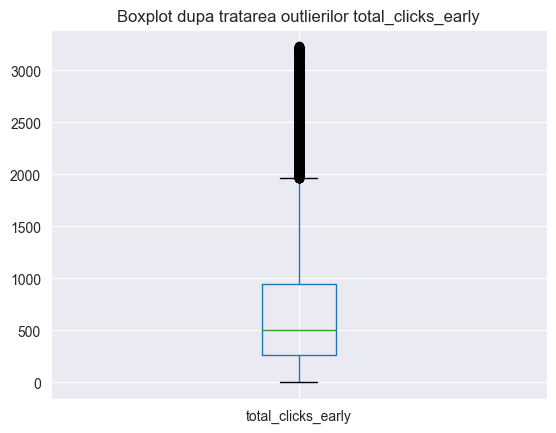

Max inainte: 12783
Max dupa: 3232.0


In [370]:
# boxplot dupa tratarea outlierilor
train_outliers.boxplot(column=feature)
plt.title(f"Boxplot dupa tratarea outlierilor {feature}")
plt.show()

print("Max inainte:", train_imputed[feature].max())
print("Max dupa:", train_outliers[feature].max())

Pe langa `total_clicks_early`, analizez si `studied_credits`, pentru ca in EDA am observat ca are valori foarte mari fata de majoritatea exemplelor. Majoritatea studentilor au intre 60 si 120 credite, dar exista si valori mult mai mari, care pot influenta modelele

In [371]:
feature = 'studied_credits'

# calculate IQR for column weighted_mean_score_early
Q1 = train_imputed[feature].quantile(0.25)
Q3 = train_imputed[feature].quantile(0.75)
IQR = Q3 - Q1

treshold = 3

lower_bound = Q1 - treshold * IQR
upper_bound = Q3 + treshold * IQR

# Identific outlierii
train_is_outlier = (train_outliers[feature] < lower_bound) | (train_outliers[feature] > upper_bound)
test_is_outlier = (test_outliers[feature] < lower_bound) | (test_outliers[feature] > upper_bound)

print("Nr. outlieri train:", train_is_outlier.sum())
print("Nr. outlieri test:", test_is_outlier.sum())

# Transform outlierii in valori lipsa
train_outliers.loc[train_is_outlier, feature] = np.nan
test_outliers.loc[test_is_outlier, feature] = np.nan

# print((train_imputed[feature] < lower_bound).sum())
# print((train_imputed[feature] > upper_bound).sum())

Nr. outlieri train: 9
Nr. outlieri test: 7


In [372]:
# Imputez outlierii cu mediana
outlier_imputer = SimpleImputer(strategy="median")

train_outliers[[feature]] = outlier_imputer.fit_transform(train_outliers[[feature]])
test_outliers[[feature]] = outlier_imputer.transform(test_outliers[[feature]])

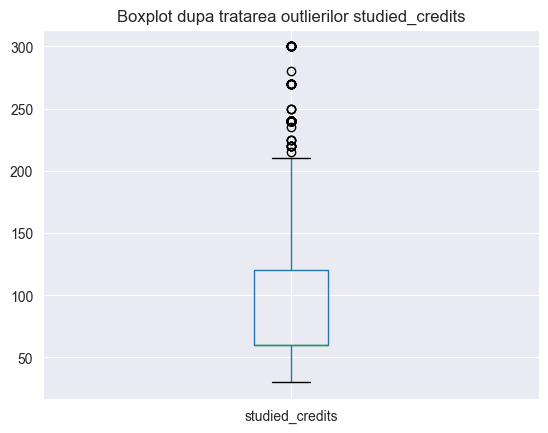

Max inainte: 430
Max dupa: 300.0


In [373]:
# boxplot dupa tratarea outlierilor
train_outliers.boxplot(column=feature)
plt.title(f"Boxplot dupa tratarea outlierilor {feature}")
plt.show()

print("Max inainte:", train_imputed[feature].max())
print("Max dupa:", train_outliers[feature].max())

### 3. (OPȚIONAL) Atribute redundante (puternic corelate)


In [374]:
train_reduced = train_outliers.copy()
test_reduced = test_outliers.copy()

In [375]:
#  Elimin atributele redundante
# redundant_features = [
#     "submission_rate_early",
#     "clicks_oucontent",
#     "date_unregistration"
# ]
# # redundant_features = [
# #     "date_unregistration"
# # ]

# train_reduced = train_outliers.drop(columns=redundant_features)
# test_reduced = test_outliers.drop(columns=redundant_features)

# print("train inainte:", train_outliers.shape)
# print("train dupa:", train_reduced.shape)

# print("test inainte:", test_outliers.shape)
# print("test dupa:", test_reduced.shape)

### Atribute redundante

Din EDA am observat cateva perechi de atribute puternic corelate:

- `submission_rate_early` si `n_assessments_early`
- `refs_oucontent` si `clicks_oucontent`

Nu elimin atribute corelate cu tintele, deoarece acestea pot fi utile pentru predictie. Elimin doar atribute care par sa contina informatii foarte asemanatoare cu alte atribute de intrare.

Pentru simplificarea setului de date:
- elimin `n_assessments_early` si pastrez `submission_rate_early`, deoarece rata de submitere mi se pare mai informativa decat numarul brut de evaluari
- elimin `refs_oucontent` si pastrez `clicks_oucontent`, deoarece `clicks_oucontent` este mai consistent/usor de interpretat


**UPDATE:** Nu mai elimin nicio coloana, intucat nu imi aduce un beneficiu, am rezultate mai bune daca le pastrez pe toate. Banuiesc ca e din cauza ca, desi unele atribute sunt corelate intre ele, ele nu sunt perfect identice si pot contine in continuare informatii utile pentru modele. De exemplu, doua atribute pot descrie acelasi comportament general al studentului, dar din perspective diferite (un atribut poate surprinde volumul total de activitate, iar altul poate surprinde rata/intensitatea acelei activitati)



### 4. Plaje valorice de mărimi diferite pentru atributele numerice

Atributele numerice au plaje de valori foarte diferite. De exemplu, unele coloane sunt rate intre 0 si 1, iar altele contin numere de clickuri de ordinul miilor

Pentru a evita ca atributele cu valori mari sa influenteze prea mult modelele liniare, aplic standardizarea atributelor numerice folosind `StandardScaler`

In [376]:
# Creez copii pentru etapa de standardizare
train_scaled = train_reduced.copy()
test_scaled = test_reduced.copy()

In [377]:
# Selectez atributele numerice
numeric_features = train_scaled.select_dtypes(include=["int64", "float64"]).columns

# Nu scalez variabilele tinta si identificatorii
columns_no_scale = ["final_coursework_score", "unregistered", "macro_stats"]
# columns_no_scale = ["final_coursework_score"]
numeric_features_to_scale = [col for col in numeric_features if col not in columns_no_scale]

# numeric_features_to_scale

In [378]:
# Aplic StandardScaler pe atributele numerice
scaler = StandardScaler()

train_scaled[numeric_features_to_scale] = scaler.fit_transform(train_scaled[numeric_features_to_scale])

test_scaled[numeric_features_to_scale] = scaler.transform(test_scaled[numeric_features_to_scale])

In [379]:
# Verific media si deviatia standard dupa standardizare
train_scaled[numeric_features].describe().transpose()

,count,mean,std,min,25%,50%,75%,max
num_of_prev_attempts,18802.0,-1.360469e-17,1.000027,-0.348765,-0.348765,-0.348765,-0.348765,12.157556
studied_credits,18802.0,8.162814e-17,1.000027,-1.374388,-0.554712,-0.554712,1.084640,6.002698
date_registration,18802.0,9.598865e-17,1.000027,-5.081558,-0.629845,0.289757,0.812259,4.908671
date_unregistration,18802.0,-4.912805e-17,1.000027,-4.234882,-0.409534,-0.409534,-0.409534,8.256050
module_presentation_length,18802.0,-1.608377e-15,1.000027,-1.653072,-1.127779,0.448100,0.898351,0.973393
n_assessments_early,18802.0,9.674446e-17,1.000027,-1.439875,-0.570019,-0.570019,0.299837,2.909405
mean_score_early,18802.0,4.111640e-16,1.000027,-4.338688,-0.449474,0.231139,0.717291,1.495134
weighted_mean_score_early,18802.0,-4.958154e-16,1.000027,-4.434061,-0.525251,0.155196,0.733571,1.604435
final_coursework_score,18802.0,7.046329e+01,16.846461,0.000000,61.000000,73.124643,83.000000,100.000000
total_clicks_early,18802.0,4.837223e-17,1.000027,-1.131839,-0.708327,-0.313912,0.390862,4.092543


Dupa standardizare, atributele numerice au media aproximativ 0 si deviatia standard aproximativ 1. Astfel, atributele numerice ajung pe scale comparabile si pot fi folosite mai corect de modele sensibile la scara valorilor

## 3.3 Utilizarea algoritmilor de Învățare Automată 


Dupa etapa de analiza si preprocesare, datele sunt pregatite pentru antrenarea modelelor de invatare automata.

In aceasta etapa voi aborda doua taskuri:
- clasificare, unde tinta este `final_result`
- regresie, unde tinta este `final_coursework_score`

Pentru inceput, voi construi modele simple, care sa functioneze ca baseline. Apoi voi incerca sa imbunatatesc rezultatele prin modificarea unor hiperparametri si prin compararea mai multor variante.

Inainte de antrenarea modelelor, trebuie sa transform atributele categoriale in valori numerice, deoarece algoritmii din scikit-learn nu pot lucra direct cu valori text

### Clasificare

Pentru taskul de clasificare, tinta este `final_result`. Aceasta este o variabila categoriala cu patru clase: `Pass`, `Fail`, `Withdrawn` si `Distinction`.

Pentru a putea antrena modele de clasificare, trebuie sa pregatesc separat:
- atributele de intrare `X`
- tinta de clasificare `y`

De asemenea, atributele categoriale trebuie encodate numeric. Pentru variabila tinta voi folosi `LabelEncoder`, iar pentru atributele categoriale de intrare voi folosi encodari potrivite in functie de tipul atributului.

In [380]:
# Separ datele pentru etapa de clasificare
X_train_class = train_scaled.drop(columns=[target_class, target_reg])
y_train_class = train_scaled[target_class]

X_test_class = test_scaled.drop(columns=[target_class, target_reg])
y_test_class = test_scaled[target_class]

In [381]:
# Encodez targetul de clasificare
label_encoder = LabelEncoder()

y_train_class_encoded = label_encoder.fit_transform(y_train_class)
y_test_class_encoded = label_encoder.transform(y_test_class)

print(label_encoder.classes_)

['Distinction' 'Fail' 'Pass' 'Withdrawn']


Am folosit `LabelEncoder` pentru tinta `final_result`, deoarece aceasta este o variabila categoriala. Clasele sunt transformate in valori numerice, astfel incat sa poata fi folosite de modelele de clasificare

### Encodarea atributelor categoriale

Pentru clasificare, algoritmii din `scikit-learn` au nevoie ca toate atributele sa fie numerice. De aceea, transform atributele categoriale in valori numerice.

Folosesc doua tipuri de encodare:
- `OneHotEncoder` pentru atribute categoriale fara ordine logica
- ordinal encoding pentru atributele care au o ordine logica

In [382]:
# Copii pentru encodare
X_train_class_encoded = X_train_class.copy()
X_test_class_encoded = X_test_class.copy()

In [383]:
# Aplic one-hot encoding pentru atributele categoriale
X_train_class_encoded = pd.get_dummies(
    X_train_class_encoded,
    columns=categorical_features,
    drop_first=True)

X_test_class_encoded = pd.get_dummies(
    X_test_class_encoded,
    columns=categorical_features,
    drop_first=True)


In [384]:
# Aplic one-hot encoding pentru atributele categoriale
# X_train_class_encoded = pd.get_dummies(
#     X_train_class_encoded,
#     columns=cat_ord_features,
#     drop_first=True)

# X_test_class_encoded = pd.get_dummies(
#     X_test_class_encoded,
#     columns=cat_ord_features,
#     drop_first=True)

### Encodarea atributelor ordinale

In [385]:
# Mapari pentru atributele ordinale
education_order = {
    "No Formal quals": 0,
    "Lower Than A Level": 1,
    "A Level or Equivalent": 2,
    "HE Qualification": 3,
    "Post Graduate Qualification": 4
}

imd_order = {
    "0-10%": 0,
    "10-20": 1,
    "20-30%": 2,
    "30-40%": 3,
    "40-50%": 4,
    "50-60%": 5,
    "60-70%": 6,
    "70-80%": 7,
    "80-90%": 8,
    "90-100%": 9
}

age_order = {
    "0-35": 0,
    "35-55": 1,
    "55<=": 2
}

clicks_freq_order = {
    "low": 0,
    "mid": 1,
    "high": 2
}

# Aplic maparile
X_train_class_encoded["highest_education"] = X_train_class_encoded["highest_education"].map(education_order)
X_test_class_encoded["highest_education"] = X_test_class_encoded["highest_education"].map(education_order)

X_train_class_encoded["imd_band"] = X_train_class_encoded["imd_band"].map(imd_order)
X_test_class_encoded["imd_band"] = X_test_class_encoded["imd_band"].map(imd_order)

X_train_class_encoded["age_band"] = X_train_class_encoded["age_band"].map(age_order)
X_test_class_encoded["age_band"] = X_test_class_encoded["age_band"].map(age_order)

X_train_class_encoded["clicks_freq_init"] = X_train_class_encoded["clicks_freq_init"].map(clicks_freq_order)
X_test_class_encoded["clicks_freq_init"] = X_test_class_encoded["clicks_freq_init"].map(clicks_freq_order)

In [386]:
# Verific dimensiunile dupa encodare
print("X_train_class_encoded:", X_train_class_encoded.shape)
print("X_test_class_encoded:", X_test_class_encoded.shape)

X_train_class_encoded: (18802, 59)
X_test_class_encoded: (4700, 59)


In [387]:
# Impart setul de train in train + validare
X_train, X_val, y_train, y_val = train_test_split(
                                X_train_class_encoded,
                                y_train_class_encoded,
                                test_size=0.2,
                                random_state=42)

### Model baseline pentru clasificare

Pentru inceput folosesc un model simplu de tip `DecisionTreeClassifier`, care va reprezenta baseline-ul pentru taskul de clasificare. Acest model va fi punctul de plecare, iar rezultatele obtinute vor fi comparate ulterior cu variante imbunatatite.

Deoarece clasele din `final_result` sunt dezechilibrate, nu ma bazez doar pe accuracy. Voi analiza si precision, recall si F1-score

In [388]:
# Creez modelul baseline
dtree_baseline = DecisionTreeClassifier(random_state=42)

# Antrenez modelul
dtree_baseline.fit(X_train, y_train)

# Predictii pe setul de validare
y_pred_dtree = dtree_baseline.predict(X_val)

# Score It
print('Baseline Decision Tree')

# Confusion Matrix
print('\n')
print('Confusion Matrix')
print(confusion_matrix(y_val, y_pred_dtree))

# Classification Report
print('--'*40)
print('Classification Report\n')
print(classification_report(y_val, y_pred_dtree, target_names=label_encoder.classes_))

# Accuracy
print('--'*40)
accuracy = accuracy_score(y_val, y_pred_dtree)
accuracy_perc = round(accuracy*100,2)
print('Acuratete procent',accuracy_perc,'%')

accuracy = accuracy_score(y_val, y_pred_dtree)
precision = precision_score(y_val, y_pred_dtree, average="macro")
recall = recall_score(y_val, y_pred_dtree, average="macro")
f1 = f1_score(y_val, y_pred_dtree, average="macro")

print("Acuratete:", round(accuracy, 3))
print("Precizie:", round(precision, 3))
print("Recall:", round(recall, 3))
print("F1:", round(f1, 3))

Baseline Decision Tree


Confusion Matrix
[[ 151   34  244    0]
 [  36  437  350    3]
 [ 204  412 1187    2]
 [   0    2    2  697]]
--------------------------------------------------------------------------------
Classification Report

              precision    recall  f1-score   support

 Distinction       0.39      0.35      0.37       429
        Fail       0.49      0.53      0.51       826
        Pass       0.67      0.66      0.66      1805
   Withdrawn       0.99      0.99      0.99       701

    accuracy                           0.66      3761
   macro avg       0.63      0.63      0.63      3761
weighted avg       0.66      0.66      0.66      3761

--------------------------------------------------------------------------------
Acuratete procent 65.73 %
Acuratete: 0.657
Precizie: 0.635
Recall: 0.633
F1: 0.634


Modelul baseline `DecisionTreeClassifier` obtine o acuratete de aproximativ 64.77%. Totusi, asa cum am observat si la analiza distributiei claselor, setul de date este dezechilibrat, deci nu este suficient sa analizez doar acuratetea.

Din raportul de clasificare rezulta ca performanta difera destul de mult intre clase:

- pentru clasa `Withdrawn`, modelul are rezultate foarte bune: precision = 0.99, recall = 1.00 si F1-score = 1.00. Acest lucru sugereaza ca modelul identifica foarte bine studentii care s-au retras. Probabil atributul `unregistered` ajuta foarte mult aici, deoarece este direct legat de retragerea studentului.
- pentru clasa `Pass`, modelul are rezultate medii-bune, cu F1-score = 0.65. Totusi, din matricea de confuzie se vede ca multe exemple din aceasta clasa sunt confundate cu `Fail` sau `Distinction`
- pentru clasa `Fail`, performanta este mai slaba, cu F1-score = 0.48. Modelul identifica o parte dintre studentii care pica, dar ii confunda destul de des cu `Pass`
- pentru clasa `Distinction`, performanta este cea mai slaba, cu F1-score = 0.38. Aceasta clasa are mai putine exemple, ceea ce poate face mai dificila invatarea ei de catre model

Valoarea F1 macro este 0.627, ceea ce arata ca performanta medie pe clase este moderata. Deoarece F1 macro trateaza clasele in mod egal, aceasta metrica este mai relevanta decat accuracy in acest caz.

In concluzie, baseline-ul obtinut este acceptabil ca punct de plecare, dar exista loc de imbunatatire, mai ales pentru clasele `Distinction` si `Fail`. In continuare voi incerca sa modific hiperparametri ai arborelui de decizie pentru a vedea daca pot obtine rezultate mai bune.

### Ablatie - Varierea hiperparametrilor pentru Decision Tree

Pornesc de la modelul baseline si modific manual cativa hiperparametri ai arborelui de decizie. Nu fac o cautare exhaustiva, ci testez cateva configuratii ca sa observ cum influenteaza acestea rezultatele.

Hiperparametrii analizati sunt:
- `max_depth`: limiteaza adancimea arborelui
- `min_samples_split`: numarul minim de exemple necesare pentru a imparti un nod
- `min_samples_leaf`: numarul minim de exemple care trebuie sa ramana intr-o frunza

Scopul este sa vad daca un arbore mai controlat obtine rezultate mai bune decat baseline-ul

In [389]:
dtree_model = DecisionTreeClassifier(
                            criterion='entropy',
                            splitter='best',
                            max_depth=10,
                            min_samples_split=4,
                            min_samples_leaf=5,
                            random_state=42)


dtree_model.fit(X_train, y_train)
y_pred_model = dtree_model.predict(X_val)

print('Decision Tree - model final')

print('\nConfusion Matrix')
print(confusion_matrix(y_val, y_pred_model))

print('--'*40)
print('Classification Report\n')
print(classification_report(y_val, y_pred_model, target_names=label_encoder.classes_))

print('--'*40)
accuracy_1 = accuracy_score(y_val, y_pred_model)
precision_1 = precision_score(y_val, y_pred_model, average="macro")
recall_1 = recall_score(y_val, y_pred_model, average="macro")
f1_1 = f1_score(y_val, y_pred_model, average="macro")

print("Acuratete:", round(accuracy_1, 3))
print("Precizie:", round(precision_1, 3))
print("Recall:", round(recall_1, 3))
print("F1:", round(f1_1, 3))

Decision Tree - model final

Confusion Matrix
[[ 107    4  318    0]
 [  13  366  447    0]
 [  85  173 1547    0]
 [   0    0    2  699]]
--------------------------------------------------------------------------------
Classification Report

              precision    recall  f1-score   support

 Distinction       0.52      0.25      0.34       429
        Fail       0.67      0.44      0.53       826
        Pass       0.67      0.86      0.75      1805
   Withdrawn       1.00      1.00      1.00       701

    accuracy                           0.72      3761
   macro avg       0.72      0.64      0.66      3761
weighted avg       0.71      0.72      0.70      3761

--------------------------------------------------------------------------------
Acuratete: 0.723
Precizie: 0.716
Recall: 0.637
F1: 0.655


### Tabel incercari

| Model | max_depth | min_samples_split | min_samples_leaf | Acc | Prec | Rec | F1 | Modificari/Obs |
|---|---:|---:|---:|---:|---:|---:|---:|---|
| baseline | None | 2 | 1 | 0.648 | 0.627 | 0.627 | 0.627 | model initial, folosit ca punct de plecare |
| model_1 | 10 | 4 | 1 | 0.721 | 0.711 | 0.651 | 0.669 | limitare adancime + min_samples_split |
| model_2 | 10 | 4 | 5 | 0.725 | 0.716 | 0.654 | 0.673 | frunze mai stabile |
| model_3 | 15 | 10 | 5 | 0.702 | 0.684 | **0.656** | 0.667 | arbore mai adanc |
| model_4 | 10 | 4 | 5 | **0.727** | **0.720** | 0.654 | **0.674** | model_2 + drop_first=True la one-hot encoding; cel mai bun F1 |
| model_5 | 10 | 4 | 5 | 0.724 | 0.716 | 0.641 | 0.660 | fara n_assessments_early, refs_oucontent si date_unregistration; performanta scade |

### Interpretarea experimentelor

**Baseline**  
Modelul de baza foloseste un `DecisionTreeClassifier` fara limitari explicite ale adancimii. Acesta obtine o acuratete de 0.648 si un F1 macro de 0.627. Il folosesc drept punct de plecare pentru a vedea daca limitarea complexitatii arborelui imbunatateste generalizarea.

**Model 1**  
Pentru `model_1` am setat `max_depth=10` si `min_samples_split=4`. Performanta creste fata de baseline, ajungand la acuratete 0.721 si F1 0.669. Acest rezultat sugereaza ca baseline-ul era prea complex si ca limitarea adancimii reduce overfitting-ul

**Model 2**  
Pentru `model_2` am pastrat `max_depth=10` si `min_samples_split=4`, dar am crescut `min_samples_leaf` la 5. Modelul obtine acuratete 0.725 si F1 0.673. Cresterea lui `min_samples_leaf` impiedica formarea unor frunze bazate pe foarte putine exemple, ceea ce ajuta modelul sa generalizeze mai bine

**Model 3**  
Pentru `model_3` am crescut adancimea la `max_depth=15` si am folosit `min_samples_split=10`, `min_samples_leaf=5`. Performanta scade fata de `model_2`, ajungand la acuratete 0.702 si F1 0.667. Acest rezultat arata ca un arbore mai adanc nu este automat mai bun si poate introduce din nou overfitting

**Model 4**  
Pentru `model_4` am pastrat hiperparametrii de la `model_2`, dar am folosit `drop_first=True` la one-hot encoding ca sa redundanta dintre coloanele dummy create pentru atributele categoriale. Acesta este cel mai bun model testat, cu acuratete 0.727 si F1 0.674. Diferenta fata de `model_2` este mica, dar arata ca o reprezentare mai compacta a atributelor categoriale poate ajuta usor modelul.

**Model 5**  
Pentru `model_5` am pastrat configuratia de la `model_4`, dar am eliminat `n_assessments_early`, `refs_oucontent` si `date_unregistration`. Am vrut sa verific daca modelul poate pastra performanta folosind doar atributul `unregistered`, fara data exacta a retragerii. Acuratetea ramane apropiata, 0.724, dar F1 score scade la 0.660. Din acest motiv, nu aleg aceasta varianta ca model final

**Concluzie**  
Cel mai bun model este `model_4`, deoarece obtine cea mai buna acuratete si cel mai bun F1 score dintre variantele testate. Configuratia finala este:

`criterion='entropy'`, `splitter='best'`, `max_depth=10`, `min_samples_split=4`, `min_samples_leaf=5`, `random_state=42`.

Pe parcursul implementarii am mai testat si alte variante, dar nu le-am pastrat deoarece nu au imbunatatit performanta:
- alte valori pentru `max_depth`, iar cea mai buna valoare observata a fost `max_depth=10`
- eliminarea tratarii outlierilor pentru `studied_credits`, dar rezultatele nu s-au imbunatatit
- folosirea one-hot encoding pentru toate atributele discrete, in locul encodarii ordinale, dar performanta nu s a imbunatatit
- variat criteriul (`gini`), dar am ramas la `entropy`, pentru ca e baza pt. ID3


**Observatie:** In etapa de regresie am ajustat tratarea outlierilor, folosind un prag mai putin agresiv de `3 * IQR` pentru `studied_credits` si `total_clicks_early`. Aceasta modificare a imbunatatit usor rezultatele pentru regresie, dar a schimbat putin si rezultatele pentru clasificare, deoarece cele doua taskuri folosesc acelasi set de date preprocesat

Am ales sa pastrez aceasta varianta de preprocesare deoarece ofera un compromis bun intre cele doua sarcini: regresia se imbunatateste, iar clasificarea ramane peste baseline si obtine in continuare rezultate bune. Modelul final de clasificare ramane `DecisionTreeClassifier` cu `max_depth=10`, `min_samples_split=4` si `min_samples_leaf=5`

### Regresie

Pentru taskul de regresie, tinta este `final_coursework_score`, adica scorul numeric obtinut de student.

Voi incepe cu un model baseline de tip `LinearRegression`, apoi incerc modele cu regularizare pentru a vedea daca pot imbunatati rezultatele. Pentru evaluare folosesc MAE, MSE, RMSE si R2.

Modelele de regresie liniara incearca sa aproximeze tinta printr-o combinatie liniara a atributelor de intrare. In cazul `LinearRegression`, modelul minimizeaza suma patratelor erorilor dintre valorile reale si cele prezise

In [390]:
# Separ datele pentru regresie
# Pentru regresie folosesc aceleasi atribute preprocesate si encodate ca la clasificare,
# dar acum targetul este final_coursework_score
X_train_reg_encoded = X_train_class_encoded.copy()
X_test_reg_encoded = X_test_class_encoded.copy()

y_train_reg = train_scaled[target_reg].copy()
y_test_reg = test_scaled[target_reg].copy()

In [391]:
# # Aplic maparile ordinale
# X_train_reg_encoded["highest_education"] = X_train_reg_encoded["highest_education"].map(education_order)
# X_test_reg_encoded["highest_education"] = X_test_reg_encoded["highest_education"].map(education_order)

# X_train_reg_encoded["imd_band"] = X_train_reg_encoded["imd_band"].map(imd_order)
# X_test_reg_encoded["imd_band"] = X_test_reg_encoded["imd_band"].map(imd_order)

# X_train_reg_encoded["age_band"] = X_train_reg_encoded["age_band"].map(age_order)
# X_test_reg_encoded["age_band"] = X_test_reg_encoded["age_band"].map(age_order)

# X_train_reg_encoded["clicks_freq_init"] = X_train_reg_encoded["clicks_freq_init"].map(clicks_freq_order)
# X_test_reg_encoded["clicks_freq_init"] = X_test_reg_encoded["clicks_freq_init"].map(clicks_freq_order)

In [392]:
# # One-hot encoding pentru atribute categoriale
# X_train_reg_encoded = pd.get_dummies(
#     X_train_reg_encoded,
#     columns=categorical_features,
#     drop_first=True
# )

# X_test_reg_encoded = pd.get_dummies(
#     X_test_reg_encoded,
#     columns=categorical_features,
#     drop_first=True
# )

In [393]:
X_train_r, X_val_r, y_train_r, y_val_r = train_test_split(
    X_train_reg_encoded,
    y_train_reg,
    test_size=0.2,
    random_state=42)

In [394]:
def evaluate_reg_model(model, X_train, y_train, X_val, y_val, model_name):
    model.fit(X_train, y_train)
    
    y_train_pred = model.predict(X_train)
    y_val_pred = model.predict(X_val)
    
    train_mae = mean_absolute_error(y_train, y_train_pred)
    val_mae = mean_absolute_error(y_val, y_val_pred)
    
    train_mse = mean_squared_error(y_train, y_train_pred)
    val_mse = mean_squared_error(y_val, y_val_pred)
    
    train_rmse = np.sqrt(train_mse)
    val_rmse = np.sqrt(val_mse)
    
    train_r2 = r2_score(y_train, y_train_pred)
    val_r2 = r2_score(y_val, y_val_pred)
    
    print(model_name)
    print("Train MAE:", round(train_mae, 3))
    print("Val MAE:", round(val_mae, 3))
    print("Train MSE:", round(train_mse, 3))
    print("Val MSE:", round(val_mse, 3))
    print("Train RMSE:", round(train_rmse, 3))
    print("Val RMSE:", round(val_rmse, 3))
    print("Train R2:", round(train_r2, 3))
    print("Val R2:", round(val_r2, 3))
    
    return {
        "Model": model_name,
        "Train MAE": train_mae,
        "Val MAE": val_mae,
        "Train MSE": train_mse,
        "Val MSE": val_mse,
        "Train RMSE": train_rmse,
        "Val RMSE": val_rmse,
        "Train R2": train_r2,
        "Val R2": val_r2
    }

In [395]:
regression_results = []

linear_baseline = LinearRegression()

result_linear = evaluate_reg_model(
    linear_baseline,
    X_train_r,
    y_train_r,
    X_val_r,
    y_val_r,
    "LinearRegression baseline"
)

regression_results.append(result_linear)

LinearRegression baseline
Train MAE: 4.993
Val MAE: 4.994
Train MSE: 49.312
Val MSE: 49.548
Train RMSE: 7.022
Val RMSE: 7.039
Train R2: 0.828
Val R2: 0.82


Modelul baseline `LinearRegression` obtine rezultate bune pentru regresie. Pe setul de validare, MAE este aproximativ 4.99, ceea ce inseamna ca, in medie, predictia scorului final difera de valoarea reala cu aproximativ 5 puncte.

Valorile pentru train si validare sunt foarte apropiate => nu face overfitting puternic, deoarece performanta pe validare este foarte apropiata de performanta pe train

Valoarea R2 de 0.82 pe validare arata ca modelul explica o parte mare din variatia scorului final. Probabil acest rezultat bun este influentat de atributele legate de scorurile obtinute devreme, cum ar fi `weighted_mean_score_early` si `mean_score_early`, care au fost puternic corelate cu `final_coursework_score` in etapa de EDA.

### Regresie cu regularizare Ridge

Dupa baseline-ul cu `LinearRegression`, testez `Ridge`, care adauga regularizare L2 asupra coeficientilor

Voi varia parametrul `alpha`, care controleaza intensitatea regularizarii (valori mai mari pentru `alpha` => o penalizare mai puternica)

In [396]:
ridge_01 = Ridge(alpha=0.01)

result_ridge_01 = evaluate_reg_model(
    ridge_01,
    X_train_r,
    y_train_r,
    X_val_r,
    y_val_r,
    "Ridge alpha=0.01")

regression_results.append(result_ridge_01)

Ridge alpha=0.01
Train MAE: 4.994
Val MAE: 4.993
Train MSE: 49.319
Val MSE: 49.54
Train RMSE: 7.023
Val RMSE: 7.038
Train R2: 0.828
Val R2: 0.82


In [397]:
ridge_01 = Ridge(alpha=0.1)

result_ridge_01 = evaluate_reg_model(
    ridge_01,
    X_train_r,
    y_train_r,
    X_val_r,
    y_val_r,
    "Ridge alpha=0.1")

regression_results.append(result_ridge_01)

Ridge alpha=0.1
Train MAE: 4.994
Val MAE: 4.993
Train MSE: 49.319
Val MSE: 49.54
Train RMSE: 7.023
Val RMSE: 7.038
Train R2: 0.828
Val R2: 0.82


In [398]:
ridge_1 = Ridge(alpha=1)

result_ridge_1 = evaluate_reg_model(
    ridge_1,
    X_train_r,
    y_train_r,
    X_val_r,
    y_val_r,
    "Ridge alpha=1")

regression_results.append(result_ridge_1)

Ridge alpha=1
Train MAE: 4.994
Val MAE: 4.993
Train MSE: 49.319
Val MSE: 49.54
Train RMSE: 7.023
Val RMSE: 7.038
Train R2: 0.828
Val R2: 0.82


In [399]:
ridge_10 = Ridge(alpha=10)

result_ridge_10 = evaluate_reg_model(
    ridge_10,
    X_train_r,
    y_train_r,
    X_val_r,
    y_val_r,
    "Ridge alpha=10")

regression_results.append(result_ridge_10)

Ridge alpha=10
Train MAE: 4.993
Val MAE: 4.993
Train MSE: 49.325
Val MSE: 49.547
Train RMSE: 7.023
Val RMSE: 7.039
Train R2: 0.828
Val R2: 0.82


In [400]:
ridge_1000 = Ridge(alpha=1000)

result_ridge_1000 = evaluate_reg_model(
    ridge_1000,
    X_train_r,
    y_train_r,
    X_val_r,
    y_val_r,
    "Ridge alpha=1000")

regression_results.append(result_ridge_1000)

Ridge alpha=1000
Train MAE: 5.192
Val MAE: 5.227
Train MSE: 51.913
Val MSE: 52.018
Train RMSE: 7.205
Val RMSE: 7.212
Train R2: 0.819
Val R2: 0.811


In [401]:
regression_results_df = pd.DataFrame(regression_results)

regression_results_df[
    [
        "Model",
        "Train MAE",
        "Val MAE",
        "Train MSE",
        "Val MSE",
        "Train RMSE",
        "Val RMSE",
        "Train R2",
        "Val R2"
    ]
].round(3)

,Model,Train MAE,Val MAE,Train MSE,Val MSE,Train RMSE,Val RMSE,Train R2,Val R2
0,LinearRegression baseline,4.993,4.994,49.312,49.548,7.022,7.039,0.828,0.820
1,Ridge alpha=0.01,4.994,4.993,49.319,49.540,7.023,7.038,0.828,0.820
2,Ridge alpha=0.1,4.994,4.993,49.319,49.540,7.023,7.038,0.828,0.820
3,Ridge alpha=1,4.994,4.993,49.319,49.540,7.023,7.038,0.828,0.820
4,Ridge alpha=10,4.993,4.993,49.325,49.547,7.023,7.039,0.828,0.820
5,Ridge alpha=1000,5.192,5.227,51.913,52.018,7.205,7.212,0.819,0.811


`LinearRegression` si `Ridge` cu valori mici/medii pentru `alpha` au rezultate aproape identice. Pentru `alpha=0.01`, `0.1`, `1` si `10`, MAE pe validare ramane aproximativ 4.992, RMSE pe validare aproximativ 7.038-7.039, iar R2 ramane 0.820

Acest lucru sugereaza ca baseline-ul liniar nu face overfitting, deoarece performanta pe train si validare este foarte apropiata. Regularizarea Ridge nu aduce o imbunatatire semnificativa pentru valori mici sau medii ale lui `alpha`

Pentru `alpha=1000`, performanta scade: Val MSE creste la 52.018, Val RMSE creste la 7.212, iar Val R2 scade la 0.811. Asta arata ca o regularizare prea puternica limiteaza prea mult coeficientii modelului si duce spre underfitting

Prin urmare, cel mai bun model ramane `LinearRegression baseline` sau un `Ridge` cu regularizare foarte mica. Deoarece rezultatele sunt aproape identice, aleg `LinearRegression` ca model final pentru regresie, fiind mai simplu si la fel de bun

### Regresie cu regularizare Lasso

Pe langa `Ridge`, am testat si `Lasso`, care foloseste regularizare L1. Spre deosebire de `Ridge`, care doar micsoreaza coeficientii, `Lasso` poate duce unii coeficienti exact la 0. Din acest motiv, poate functiona si ca o forma de selectie a atributelor.

Ca si la Ridge, parametrul `alpha` controleaza cat de puternica este regularizarea:
- daca `alpha` e mic, modelul este foarte apropiat de regresia liniara simpla
- daca `alpha` e mare, regularizarea este mai puternica si modelul devine mai simplu
- in cazul meu, daca regularizarea e prea puternica, modelul poate ajunge la underfitting



In [402]:
lasso_001 = Lasso(alpha=0.001, max_iter=10000)

result_lasso_001 = evaluate_reg_model(
    lasso_001,
    X_train_r,
    y_train_r,
    X_val_r,
    y_val_r,
    "Lasso alpha=0.001")

regression_results.append(result_lasso_001)

Lasso alpha=0.001
Train MAE: 4.992
Val MAE: 4.993
Train MSE: 49.321
Val MSE: 49.543
Train RMSE: 7.023
Val RMSE: 7.039
Train R2: 0.828
Val R2: 0.82


In [403]:
lasso_001 = Lasso(alpha=0.01, max_iter=10000)

result_lasso_001 = evaluate_reg_model(
    lasso_001,
    X_train_r,
    y_train_r,
    X_val_r,
    y_val_r,
    "Lasso alpha=0.01")

regression_results.append(result_lasso_001)

Lasso alpha=0.01
Train MAE: 4.988
Val MAE: 4.993
Train MSE: 49.397
Val MSE: 49.572
Train RMSE: 7.028
Val RMSE: 7.041
Train R2: 0.827
Val R2: 0.82


In [404]:
lasso_01 = Lasso(alpha=0.1, max_iter=10000)

result_lasso_01 = evaluate_reg_model(
    lasso_01,
    X_train_r,
    y_train_r,
    X_val_r,
    y_val_r,
    "Lasso alpha=0.1")

regression_results.append(result_lasso_01)

Lasso alpha=0.1
Train MAE: 5.052
Val MAE: 5.08
Train MSE: 50.703
Val MSE: 50.792
Train RMSE: 7.121
Val RMSE: 7.127
Train R2: 0.823
Val R2: 0.815


In [405]:
lasso_1 = Lasso(alpha=1, max_iter=10000)

result_lasso_1 = evaluate_reg_model(
    lasso_1,
    X_train_r,
    y_train_r,
    X_val_r,
    y_val_r,
    "Lasso alpha=1")

regression_results.append(result_lasso_1)

Lasso alpha=1
Train MAE: 5.414
Val MAE: 5.477
Train MSE: 55.79
Val MSE: 55.796
Train RMSE: 7.469
Val RMSE: 7.47
Train R2: 0.805
Val R2: 0.797


In [406]:
regression_results_df = pd.DataFrame(regression_results)

regression_results_df[
    [
        "Model",
        "Train MAE",
        "Val MAE",
        "Train MSE",
        "Val MSE",
        "Train RMSE",
        "Val RMSE",
        "Train R2",
        "Val R2"
    ]
].round(3)

,Model,Train MAE,Val MAE,Train MSE,Val MSE,Train RMSE,Val RMSE,Train R2,Val R2
0,LinearRegression baseline,4.993,4.994,49.312,49.548,7.022,7.039,0.828,0.820
1,Ridge alpha=0.01,4.994,4.993,49.319,49.540,7.023,7.038,0.828,0.820
2,Ridge alpha=0.1,4.994,4.993,49.319,49.540,7.023,7.038,0.828,0.820
3,Ridge alpha=1,4.994,4.993,49.319,49.540,7.023,7.038,0.828,0.820
4,Ridge alpha=10,4.993,4.993,49.325,49.547,7.023,7.039,0.828,0.820
5,Ridge alpha=1000,5.192,5.227,51.913,52.018,7.205,7.212,0.819,0.811
6,Lasso alpha=0.001,4.992,4.993,49.321,49.543,7.023,7.039,0.828,0.820
7,Lasso alpha=0.01,4.988,4.993,49.397,49.572,7.028,7.041,0.827,0.820
8,Lasso alpha=0.1,5.052,5.080,50.703,50.792,7.121,7.127,0.823,0.815
9,Lasso alpha=1,5.414,5.477,55.790,55.796,7.469,7.470,0.805,0.797


Pentru `Lasso alpha=0.001`, rezultatele sunt aproape identice cu cele obtinute de `LinearRegression`. Acest lucru este normal, deoarece valoarea lui `alpha` este foarte mica, deci regularizarea este slaba si modelul ramane foarte apropiat de regresia liniara simpla

Pentru valori mai mari ale lui `alpha`, performanta incepe sa scada. Se observa ca MAE, MSE si RMSE cresc, iar R2 scade. Acest lucru sugereaza ca regularizarea L1 devine prea puternica si elimina/reduce prea mult influenta unor atribute utile

In concluzie, nici `Lasso` nu aduce o imbunatatire fata de baseline-ul `LinearRegression`


Am testat doua tipuri de regularizare: `Ridge` si `Lasso` si am observat rezuoltate similare: pentru valori mici si medii ale lui `alpha`, rezultatele sunt foarte apropiate de cele obtinute de `LinearRegression`. Acest lucru sugereaza ca modelul baseline nu face overfitting, deoarece performanta pe train si test sunt foarte apropiate

Pentru valori mari ale lui `alpha`, atat la `Ridge`, cat si la `Lasso`, performanta scade. MAE, MSE si RMSE cresc, iar R2 scade. Acest lucru arata ca regularizarea prea puternica simplifica prea mult modelul si duce la underfitting

Prin urmare, pentru taskul de regresie aleg `LinearRegression` ca model final. Este cel mai simplu model si are rezultate cel putin la fel de bune ca variantele regularizate

In [407]:
# Fac un plot ca sa vad mai bine evolutia erorilor
plot_df = regression_results_df.copy()

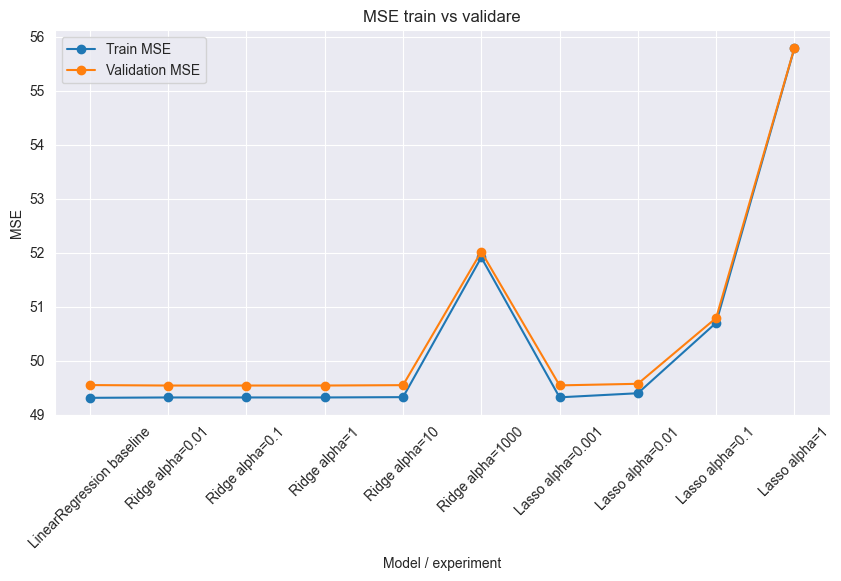

In [408]:
plt.figure(figsize=(10, 5))

plt.plot(
    plot_df["Model"],
    plot_df["Train MSE"],
    marker="o",
    label="Train MSE"
)

plt.plot(
    plot_df["Model"],
    plot_df["Val MSE"],
    marker="o",
    label="Validation MSE"
)

plt.title("MSE train vs validare")
plt.xlabel("Model / experiment")
plt.ylabel("MSE")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.show()

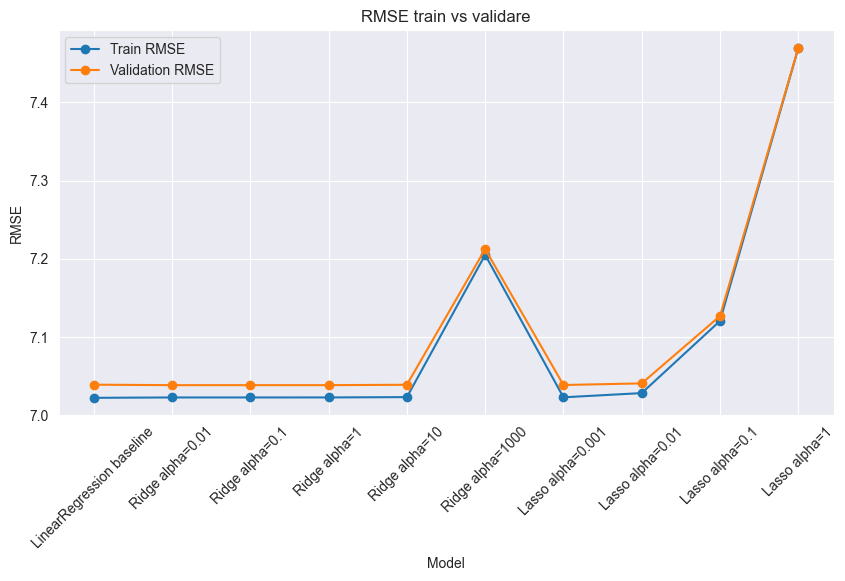

In [409]:
plt.figure(figsize=(10, 5))

plt.plot(
    plot_df["Model"],
    plot_df["Train RMSE"],
    marker="o",
    label="Train RMSE"
)

plt.plot(
    plot_df["Model"],
    plot_df["Val RMSE"],
    marker="o",
    label="Validation RMSE"
)

plt.title("RMSE train vs validare")
plt.xlabel("Model")
plt.ylabel("RMSE")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.show()

Din grafice se observa ca erorile pe train si validare sunt foarte apropiate pentru `LinearRegression` si pentru modelele regularizate cu valori mici ale lui `alpha` => modelul nu face overfitting

Pentru valori mari ale regularizarii, de exemplu `Ridge alpha=1000` sau `Lasso alpha=1`, erorile cresc atat pe train, cat si pe validare => underfitting, deoarece modelul devine prea simplu.

In [410]:
# Model final pentru regresie
final_reg_model = LinearRegression()

# Antrenez pe tot setul de train
final_reg_model.fit(X_train_reg_encoded, y_train_reg)

# Predictii pe setul de test
y_test_reg_pred = final_reg_model.predict(X_test_reg_encoded)

# Metrici pe test
test_mae = mean_absolute_error(y_test_reg, y_test_reg_pred)
test_mse = mean_squared_error(y_test_reg, y_test_reg_pred)
test_rmse = np.sqrt(test_mse)
test_r2 = r2_score(y_test_reg, y_test_reg_pred)

print("LinearRegression - test set")
print("Test MAE:", round(test_mae, 3))
print("Test MSE:", round(test_mse, 3))
print("Test RMSE:", round(test_rmse, 3))
print("Test R2:", round(test_r2, 3))

LinearRegression - test set
Test MAE: 5.07
Test MSE: 51.225
Test RMSE: 7.157
Test R2: 0.808


In [411]:
final_ridge_model = Ridge(alpha=0.01)

final_ridge_model.fit(X_train_reg_encoded, y_train_reg)

y_test_ridge_pred = final_ridge_model.predict(X_test_reg_encoded)

test_mae_ridge = mean_absolute_error(y_test_reg, y_test_ridge_pred)
test_mse_ridge = mean_squared_error(y_test_reg, y_test_ridge_pred)
test_rmse_ridge = np.sqrt(test_mse_ridge)
test_r2_ridge = r2_score(y_test_reg, y_test_ridge_pred)

print("Ridge alpha=0.01 - test set")
print("Test MAE:", round(test_mae_ridge, 3))
print("Test MSE:", round(test_mse_ridge, 3))
print("Test RMSE:", round(test_rmse_ridge, 3))
print("Test R2:", round(test_r2_ridge, 3))

Ridge alpha=0.01 - test set
Test MAE: 5.071
Test MSE: 51.236
Test RMSE: 7.158
Test R2: 0.808


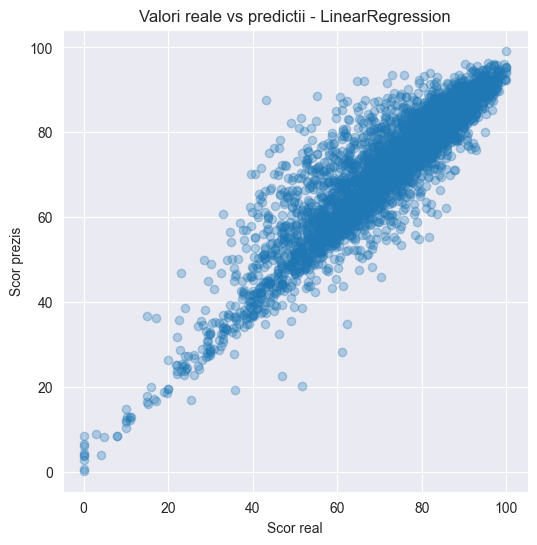

In [412]:
plt.figure(figsize=(6, 6))

y_val_pred = linear_baseline.predict(X_val_r)

plt.scatter(y_val_r, y_val_pred, alpha=0.3)


plt.plot()

plt.title("Valori reale vs predictii - LinearRegression")
plt.xlabel("Scor real")
plt.ylabel("Scor prezis")
plt.grid(True)
plt.show()

Din graficul valorilor reale vs predictii se observa ca majoritatea punctelor sunt apropiate de diagonala. Acest lucru inseamna ca modelul prezice destul de bine scorul final, iar predictiile sunt apropiate de valorile reale.

Totusi, exista si cateva puncte mai indepartate de diagonala, mai ales in zona scorurilor medii. Aceste exemple reprezinta cazuri unde modelul are erori mai mari. De aceea RMSE este mai mare decat MAE ( RMSE penalizeaza mai puternic aceste erori mari)

### Modificari si experimente

- Am testat si tratarea outlierilor pentru scorurile early, dar rezultatele s-au inrautatit. Val MAE a crescut de la 4.992 la 5.287, iar Val RMSE a crescut de la 7.039 la 7.402. In acelasi timp, Val R2 a scazut de la 0.820 la 0.801

Acest lucru sugereaza ca valorile extreme ale scorurilor early nu sunt doar zgomot, ci reprezinta informatie utila despre performanta studentilor. Din acest motiv, nu pastrez aceasta modificare in varianta finala.

- Am testat si un prag mai mare pentru metoda IQR (`3 * IQR` in loc de `1.5 * IQR`) la `studied_credits` si `total_clicks_early`. Aceasta varianta este mai putin agresiva, deoarece trateaza doar valorile foarte extreme.

Rezultatele sunt foarte apropiate de varianta initiala, dar usor mai bune. Din acest motiv, pastrez pragul `3 * IQR`, deoarece permite pastrarea mai multor valori reale din date.

- Desi am incercat sa elimin unele atribute considerate redundante in etapa de EDA, rezultatele nu s-au imbunatatit. Modelul a performat putin mai bine atunci cand am pastrat toate atributele. De aceeaa am decis sa nu elimin nicio coloana, deoarece ele pot contine in continuare informatie utila pentru model

## Evaluarea algoritmilor

### Evaluare clasificare

Pentru clasificare, cel mai bun model obtinut a fost un `DecisionTreeClassifier`. Acesta a fost ales in urma experimentelor facute anterior, unde am variat hiperparametri precum `max_depth`, `min_samples_split` si `min_samples_leaf`.

Hiperparametrii finali folositi sunt:

- `criterion = entropy`
- `splitter = best`
- `max_depth = 10`
- `min_samples_split = 4`
- `min_samples_leaf = 5`
- `random_state = 42`

Am ales acest model deoarece a avut cel mai bun echilibru intre acuratete si F1 pe setul de validare (si pe cel de testare). Deoarece clasele sunt dezechilibrate, nu m-am bazat doar pe acuratete, ci am urmarit si precision, recall si F1 score si l-am ales pe cel mai bun overall

In [413]:
# Model final ales dupa experimentele pe validare
final_dtree = DecisionTreeClassifier(
                            criterion='entropy',
                            splitter='best',
                            max_depth=10,
                            min_samples_split=4,
                            min_samples_leaf=5,
                            random_state=42)

# Antrenez modelul final pe tot setul de train
final_dtree.fit(X_train_class_encoded, y_train_class_encoded)

# Predictii pe setul de test
y_test_pred = final_dtree.predict(X_test_class_encoded)

print("Decision Tree - test set")

print("\nConfusion Matrix")
print(confusion_matrix(y_test_class_encoded, y_test_pred))

print("--" * 40)
print("Classification Report\n")
print(classification_report(
    y_test_class_encoded,
    y_test_pred,
    target_names=label_encoder.classes_
))

print("--" * 40)
test_accuracy = accuracy_score(y_test_class_encoded, y_test_pred)
test_precision = precision_score(y_test_class_encoded, y_test_pred, average="macro")
test_recall = recall_score(y_test_class_encoded, y_test_pred, average="macro")
test_f1 = f1_score(y_test_class_encoded, y_test_pred, average="macro")

print("Acuratete:", round(test_accuracy, 3))
print("Precizie:", round(test_precision, 3))
print("Recall:", round(test_recall, 3))
print("F1:", round(test_f1, 3))

Decision Tree - test set

Confusion Matrix
[[ 162    7  357    0]
 [   6  486  547    0]
 [  92  189 1966    0]
 [   0    3    0  885]]
--------------------------------------------------------------------------------
Classification Report

              precision    recall  f1-score   support

 Distinction       0.62      0.31      0.41       526
        Fail       0.71      0.47      0.56      1039
        Pass       0.69      0.87      0.77      2247
   Withdrawn       1.00      1.00      1.00       888

    accuracy                           0.74      4700
   macro avg       0.75      0.66      0.69      4700
weighted avg       0.74      0.74      0.73      4700

--------------------------------------------------------------------------------
Acuratete: 0.744
Precizie: 0.754
Recall: 0.662
F1: 0.686


Din raportul de clasificare se vede ca modelul nu se comporta la fel pentru toate clasele.

Clasa `Withdrawn` este identificata aproape perfect, cu precision, recall si F1 score egale cu 1.00. Acest rezultat este influentat clar de atributul `unregistered`, care indica direct daca studentul s-a retras.

Pentru clasa `Pass`, modelul are rezultate bune: recall = 0.87 si F1 score = 0.77. Recall-ul mare arata ca majoritatea studentilor care au promovat sunt gasiti corect. Totusi, precision-ul este 0.69, deci modelul mai prezice `Pass` si pentru exemple din alte clase. Acest lucru are sens, pentru ca `Pass` este cea mai numeroasa clasa din test, iar modelul tinde sa favorizeze aceasta clasa

Pentru `Fail`, modelul are precision = 0.71, dar recall = 0.47. Asta inseamna ca atunci cand prezice `Fail`, de multe ori are dreptate, dar rateaza destul de multi studenti care chiar au picat. Multi dintre ei sunt confundati cu `Pass`

Cea mai slaba clasa este `Distinction`, cu F1 score = 0.41 si recall = 0.31. Modelul identifica putini studenti din aceasta clasa si ii confunda des cu `Pass`. Probabil se intampla asta pentru ca `Distinction` are mai putine exemple si este apropiata de `Pass`, ambele fiind clase de promovare,apropiate cumva , cu scoruri mari

Acuratetea finala este 0.744, iar F1 score-ul este 0.686. Aleg acest model deoarece are rezultate bune per total, reduce overfitting-ul fata de arborele initial si pastreaza un echilibru mai bun intre clase

### Evaluare regresie

Pentru regresie, modelul final ales este `LinearRegression`. Acesta a fost ales deoarece a avut rezultate foarte bune pe validare, iar modelele regularizate `Ridge` si `Lasso` nu au adus o imbunatatire semnificativa. 

OBS: Probabil trebuia sa fac arbori de regresie, dar timpul nu prea a tinut cu mine (e 6:52 AM :')))

Hiperparametrii finali folositi sunt cei impliciti ai clasei `LinearRegression`.

Am testat si regularizare:
- `Ridge`, cu regularizare L2 si valori diferite pentru `alpha`
- `Lasso`, cu regularizare L1 si valori diferite pentru `alpha`

Rezultatele au aratat ca regularizarea mica produce rezultate aproape identice cu regresia liniara simpla, iar regularizarea prea puternica duce la underfitting

In [414]:
# Aceleasi modele/configuratii testate anterior pe validare
regression_models = [
    ("LinearRegression", LinearRegression()),

    ("Ridge alpha=0.001", Ridge(alpha=0.001)),
    ("Ridge alpha=0.01", Ridge(alpha=0.01)),
    ("Ridge alpha=0.1", Ridge(alpha=0.1)),
    ("Ridge alpha=1", Ridge(alpha=1)),
    ("Ridge alpha=10", Ridge(alpha=10)),
    ("Ridge alpha=1000", Ridge(alpha=1000)),

    ("Lasso alpha=0.001", Lasso(alpha=0.001, max_iter=10000)),
    ("Lasso alpha=0.01", Lasso(alpha=0.01, max_iter=10000)),
    ("Lasso alpha=0.1", Lasso(alpha=0.1, max_iter=10000)),
    ("Lasso alpha=1", Lasso(alpha=1, max_iter=10000)),
    ("Lasso alpha=10", Lasso(alpha=10, max_iter=10000)),
    ("Lasso alpha=100", Lasso(alpha=100, max_iter=10000)),
]

test_results = []

for model_name, model in regression_models:
    model.fit(X_train_reg_encoded, y_train_reg)

    y_train_pred = model.predict(X_train_reg_encoded)
    y_test_pred = model.predict(X_test_reg_encoded)

    train_mse = mean_squared_error(y_train_reg, y_train_pred)
    test_mse = mean_squared_error(y_test_reg, y_test_pred)

    test_results.append({
        "Model": model_name,
        "Train MAE": mean_absolute_error(y_train_reg, y_train_pred),
        "Test MAE": mean_absolute_error(y_test_reg, y_test_pred),
        "Train MSE": train_mse,
        "Test MSE": test_mse,
        "Train RMSE": np.sqrt(train_mse),
        "Test RMSE": np.sqrt(test_mse),
        "Train R2": r2_score(y_train_reg, y_train_pred),
        "Test R2": r2_score(y_test_reg, y_test_pred)
    })

test_results_df = pd.DataFrame(test_results)
test_results_df.round(3)

,Model,Train MAE,Test MAE,Train MSE,Test MSE,Train RMSE,Test RMSE,Train R2,Test R2
0,LinearRegression,4.995,5.070,49.297,51.225,7.021,7.157,0.826,0.808
1,Ridge alpha=0.001,4.995,5.071,49.301,51.236,7.021,7.158,0.826,0.808
2,Ridge alpha=0.01,4.995,5.071,49.301,51.236,7.021,7.158,0.826,0.808
3,Ridge alpha=0.1,4.995,5.071,49.301,51.236,7.021,7.158,0.826,0.808
4,Ridge alpha=1,4.995,5.071,49.301,51.236,7.021,7.158,0.826,0.808
5,Ridge alpha=10,4.995,5.070,49.305,51.234,7.022,7.158,0.826,0.808
6,Ridge alpha=1000,5.156,5.237,51.310,52.885,7.163,7.272,0.819,0.802
7,Lasso alpha=0.001,4.994,5.069,49.303,51.236,7.022,7.158,0.826,0.808
8,Lasso alpha=0.01,4.991,5.057,49.384,51.240,7.027,7.158,0.826,0.808
9,Lasso alpha=0.1,5.057,5.110,50.682,52.278,7.119,7.230,0.821,0.804


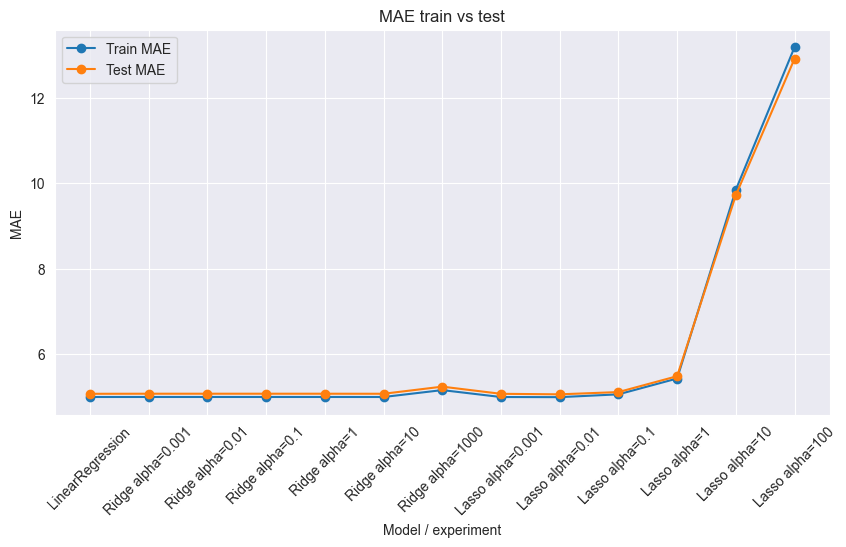

In [415]:
plt.figure(figsize=(10, 5))

plt.plot(
    test_results_df["Model"],
    test_results_df["Train MAE"],
    marker="o",
    label="Train MAE")

plt.plot(
    test_results_df["Model"],
    test_results_df["Test MAE"],
    marker="o",
    label="Test MAE")

plt.title("MAE train vs test")
plt.xlabel("Model / experiment")
plt.ylabel("MAE")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.show()

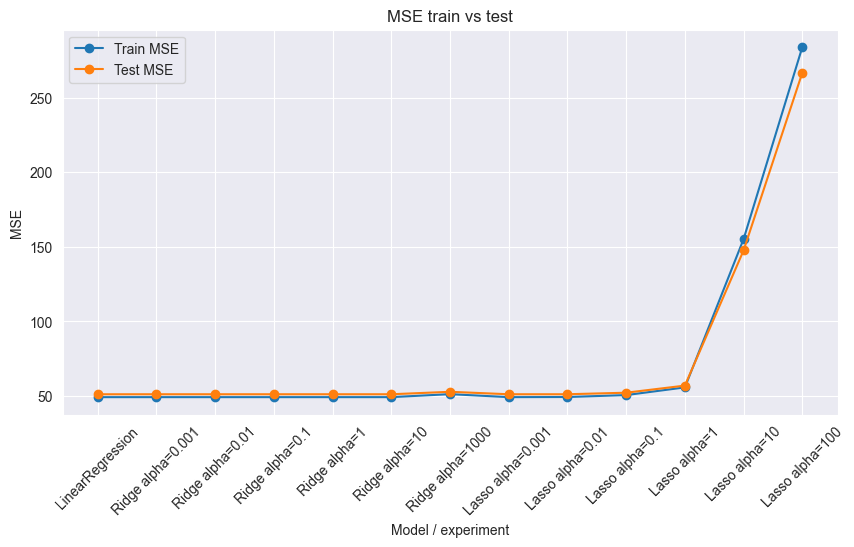

In [416]:
plt.figure(figsize=(10, 5))

plt.plot(
    test_results_df["Model"],
    test_results_df["Train MSE"],
    marker="o",
    label="Train MSE"
)

plt.plot(
    test_results_df["Model"],
    test_results_df["Test MSE"],
    marker="o",
    label="Test MSE"
)

plt.title("MSE train vs test")
plt.xlabel("Model / experiment")
plt.ylabel("MSE")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.show()

### Interpretarea rezultatelor pe setul de test

Pe setul de test, `LinearRegression`, `Ridge` cu alpha mic si `Lasso` cu alpha mic au rezultate foarte apropiate. Asta imi arata ca un model liniar simplu surprinde deja destul de bine relatia dintre atribute si `final_coursework_score`, iar regularizarea slaba nu aduce o imbunatatire ssemnificativa (lucru  explicat de corelatia pearson mare dintre `weighted_mean_score_early` si `final_coursework_score`, observata in EDA)

La Ridge, pentru alpha intre 0.01 si 10 rezultatele sunt practic identice cu LinearRegression. Abia pentru alpha=1000 apare degradare vizibila, deoarece regularizarea devine suficient de puternica sa distorsioneze coeficientii

Diferentele mici dintre train si test pentru modelele bune arata ca acestea generalizeaza bine => aleg `LinearRegression` ca model final, deoarece obtine cel mai bun MSE si RMSE pe test si e si cel mai simplu model

Ca sa obtin performante mai bune, asa cum am zis si mai sus, probabil trebuia sa fac arbori de regresie, dar deoarece timpul a fost limitat, am incercat sa inteleg si sa fac partile cele mai importante si de baza 

### Hiperparametri finali

| Task | Model final | Hiperparametri |
|---|---|---|
| Clasificare | DecisionTreeClassifier | criterion='entropy', splitter='best', max_depth=10, min_samples_split=4, min_samples_leaf=5, random_state=42 |
| Regresie | LinearRegression | model simplu, fara regularizre |

### Concluzii

#### Clasificare:

Consier ca DecisionTreeClassifier cu max_depth=10, min_samples_split=4 si min_samples_leaf=5 obtine cel mai bun rezultat in principal datorita limitarii complexitatii arborelui. Baseline-ul fara restrictii facea overfitting, iar limitarea adancimii combinata cu min_samples_leaf=5 a fortat modelul sa invete pattern-uri mai generale, nu sa memoreze cazuri izolate
Un alt factor important a fost crearea atributului unregistered — clasa Withdrawn este identificata aproape perfect (F1 = 1.00), ceea ce arata ca acest semnal binar a fost extrem de util. De asemenea, tratarea outlierilor pentru total_clicks_early a eliminat valori extreme care ar fi putut distorsiona split-urile din arbore.
Clasa Distinction ramane cea mai greu de prezis chiar si in modelul final, ceea ce cred ca se datoreaza dezechilibrului de clase — modelul vede mai putine exemple pentru aceasta clasa si nu reuseste sa invete la fel de bine ca pentru celelalte

#### Regresie:

LinearRegression obtine rezultate foarte bune, deoarece relatia dintre atribute si final_coursework_score este aproape liniara — atribute precum weighted_mean_score_early si mean_score_early sunt puternic corelate cu tinta, asa cum am observat si in EDA. Intr-un astfel de context, un model simplu este suficient si regularizarea nu aduce un beneficiu semnificativ. Ridge si Lasso cu alpha mic dau rezultate aproape identice cu baseline-ul, iar pentru alpha mare apare underfitting, deoarece penalizarea devine prea puternica si elimina informatie utila

#### In general...

Mi-a placut tema si mi s-a parut chiar interesant ca a trebuit sa parcurgem toti pasii. Am obtinut niste rezultate interesante, unele chiar contraintuitive la inceput, si mi-a placut partea in care a trebuit sa caut sensul lor si sa inteleg de ce se intampla anumite lucruri (sper ca mi-a iesit :))

Imi pare rau ca nu m-am organizat mai bine cu timpul, pentru ca as fi vrut sa incerc mai multi algoritmi pentru optimizare (arbori de regresie, random forest si poate regresie logistica pentru clasificare). Totusi, cred ca solutia finala este coerenta si ca am reusit sa inteleg mai bine pasii principali si introducerea in ML